<a href="https://colab.research.google.com/github/najeemadelakun/MSC501-M5-Distributed-Processing/blob/main/MSC501_M5_Distributed_Processing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# ============================================================
# MSC501 M5.5: DISTRIBUTED PROCESSING SUBSYSTEM
# STAGE 1: ENVIRONMENT AND PROJECT INITIALISATION
# ============================================================

from pathlib import Path
import subprocess
import sys
import os

# 1. GitHub repository
REPOSITORY_URL = (
    "https://github.com/najeemadelakun/"
    "MSC501-M5-Distributed-Processing.git"
)

PROJECT_NAME = "MSC501-M5-Distributed-Processing"

# 2. Clone repository only if it does not already exist
PROJECT_DIR = Path("/content") / PROJECT_NAME

if not PROJECT_DIR.exists():
    subprocess.run(
        ["git", "clone", REPOSITORY_URL, str(PROJECT_DIR)],
        check=True
    )
else:
    print("Existing project directory detected.")

os.chdir(PROJECT_DIR)

# 3. Create project directories
DIRECTORIES = [
    "src",
    "tests",
    "benchmarks",
    "diagrams",
    "results",
    "reports"
]

for directory in DIRECTORIES:
    (PROJECT_DIR / directory).mkdir(
        parents=True,
        exist_ok=True
    )

# 4. Define project dependencies
REQUIREMENTS = """
numpy
pandas
matplotlib
scipy
pytest
pytest-cov
hypothesis
"""

(PROJECT_DIR / "requirements.txt").write_text(
    REQUIREMENTS.strip() + "\n",
    encoding="utf-8"
)

# 5. Install dependencies once
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-r",
        "requirements.txt"
    ],
    check=True
)

# 6. Verify installed dependencies
import numpy
import pandas
import matplotlib
import scipy
import pytest
import hypothesis

# 7. Display project configuration
print("\n" + "=" * 65)
print("MSC501 M5.5 PROJECT INITIALISATION")
print("=" * 65)

print(f"Project directory: {PROJECT_DIR}")
print(f"Python version: {sys.version.split()[0]}")
print(f"NumPy: {numpy.__version__}")
print(f"Pandas: {pandas.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"SciPy: {scipy.__version__}")
print(f"Pytest: {pytest.__version__}")

print("\nPROJECT DIRECTORIES")
for directory in DIRECTORIES:
    print(f"[PASS] {directory}/")

print("\n[PASS] GitHub repository cloned or existing directory reused.")
print("[PASS] Project directories created.")
print("[PASS] Dependencies installed and imported.")
print("[PASS] Environment initialisation completed.")
print("=" * 65)



MSC501 M5.5 PROJECT INITIALISATION
Project directory: /content/MSC501-M5-Distributed-Processing
Python version: 3.13.18
NumPy: 2.4.6
Pandas: 2.2.3
Matplotlib: 3.10.0
SciPy: 1.16.3
Pytest: 8.4.2

PROJECT DIRECTORIES
[PASS] src/
[PASS] tests/
[PASS] benchmarks/
[PASS] diagrams/
[PASS] results/
[PASS] reports/

[PASS] GitHub repository cloned or existing directory reused.
[PASS] Project directories created.
[PASS] Dependencies installed and imported.
[PASS] Environment initialisation completed.


In [3]:

# ============================================================
# MSC501 M5.5
# STAGE 2A: REPAIR GENERATED SOURCE FILES
# ============================================================

from pathlib import Path
import sys
import subprocess

PROJECT_DIR = Path("/content/MSC501-M5-Distributed-Processing")

FILES_TO_REPAIR = [
    "src/__init__.py",
    "src/config.py",
    "src/models.py",
    "src/validator.py",
    "tests/test_stage2.py",
    "requirements.txt"
]

print("=" * 65)
print("REPAIRING GENERATED PROJECT FILES")
print("=" * 65)

for relative_path in FILES_TO_REPAIR:
    file_path = PROJECT_DIR / relative_path

    if not file_path.exists():
        raise FileNotFoundError(f"Missing file: {relative_path}")

    content = file_path.read_text(encoding="utf-8")

    # Remove literal escaped newline characters at file endings
    while content.endswith("\\n"):
        content = content[:-2]

    # Write using a genuine newline character
    file_path.write_text(content + "\n", encoding="utf-8")

    print(f"[PASS] Repaired {relative_path}")

# Ensure the project directory is importable
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# Verify module imports
from src.config import SystemConfig, DEFAULT_CONFIG
from src.models import ProcessingRequest, ProcessingResult
from src.validator import validate_request

print("\n[PASS] All source modules imported successfully.")

# Run the Stage 2 tests
result = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_stage2.py", "-v", "--tb=short"
    ],
    cwd=PROJECT_DIR,
    capture_output=True,
    text=True
)

print("\nAUTOMATED TEST RESULTS")
print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Stage 2 tests require further correction.")

print("[PASS] Stage 2 verification completed.")
print("=" * 65)


REPAIRING GENERATED PROJECT FILES
[PASS] Repaired src/__init__.py
[PASS] Repaired src/config.py
[PASS] Repaired src/models.py
[PASS] Repaired src/validator.py
[PASS] Repaired tests/test_stage2.py
[PASS] Repaired requirements.txt

[PASS] All source modules imported successfully.

AUTOMATED TEST RESULTS
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
hypothesis profile 'default'
rootdir: /content/MSC501-M5-Distributed-Processing
plugins: cov-7.1.0, hypothesis-6.170.15, langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collecting ... collected 8 items

tests/test_stage2.py::test_default_configuration PASSED                  [ 12%]
tests/test_stage2.py::test_invalid_configuration PASSED                  [ 25%]
tests/test_stage2.py::test_request_creation PASSED                       [ 37%]
tests/test_stage2.py::test_valid_request PASSE

In [4]:

# ============================================================
# MSC501 M5.5
# STAGE 3: QUEUEING THEORY AND LOAD MANAGEMENT
# ============================================================

from pathlib import Path
import subprocess
import sys

PROJECT_DIR = Path("/content/MSC501-M5-Distributed-Processing")
SRC_DIR = PROJECT_DIR / "src"
TEST_DIR = PROJECT_DIR / "tests"

# ------------------------------------------------------------
# 1. M/M/c QUEUEING THEORY MODEL
# ------------------------------------------------------------

(SRC_DIR / "queueing_model.py").write_text("""
import math


def analyse_queue(arrival_rate, service_rate, workers):
    '''
    Analyse an M/M/c queue using the Erlang C model.

    arrival_rate: requests arriving per second
    service_rate: requests processed per second by each worker
    workers: number of parallel workers
    '''

    if arrival_rate < 0:
        raise ValueError("Arrival rate cannot be negative")

    if service_rate <= 0:
        raise ValueError("Service rate must be positive")

    if workers < 1:
        raise ValueError("Workers must be at least one")

    capacity = workers * service_rate
    utilisation = arrival_rate / capacity

    result = {
        "arrival_rate": arrival_rate,
        "service_rate_per_worker": service_rate,
        "workers": workers,
        "theoretical_capacity": capacity,
        "utilisation": utilisation,
        "stable": utilisation < 1
    }

    if arrival_rate == 0:
        result.update({
            "probability_wait": 0.0,
            "average_queue_length": 0.0,
            "average_waiting_time_s": 0.0,
            "average_system_time_s": 1 / service_rate,
            "average_system_length": 0.0
        })
        return result

    if utilisation >= 1:
        result.update({
            "probability_wait": None,
            "average_queue_length": math.inf,
            "average_waiting_time_s": math.inf,
            "average_system_time_s": math.inf,
            "average_system_length": math.inf
        })
        return result

    offered_load = arrival_rate / service_rate

    # Calculate the Erlang C denominator.
    terms = [
        (offered_load ** k) / math.factorial(k)
        for k in range(workers)
    ]

    final_term = (
        (offered_load ** workers)
        / math.factorial(workers)
        / (1 - utilisation)
    )

    denominator = sum(terms) + final_term
    probability_zero = 1 / denominator

    probability_wait = final_term * probability_zero

    # Expected queue waiting time.
    waiting_time = (
        probability_wait / (capacity - arrival_rate)
    )

    # Little's Law.
    average_queue_length = arrival_rate * waiting_time

    average_system_time = waiting_time + (1 / service_rate)

    average_system_length = (
        arrival_rate * average_system_time
    )

    result.update({
        "probability_wait": probability_wait,
        "average_queue_length": average_queue_length,
        "average_waiting_time_s": waiting_time,
        "average_system_time_s": average_system_time,
        "average_system_length": average_system_length
    })

    return result
""".strip() + "\n", encoding="utf-8")


# ------------------------------------------------------------
# 2. LOAD MANAGEMENT MODULE
# ------------------------------------------------------------

(SRC_DIR / "load_manager.py").write_text("""
import math


def recommend_workers(
    arrival_rate,
    service_rate,
    target_utilisation=0.80,
    max_workers=None
):
    '''
    Estimate the worker count required to keep utilisation
    at or below a specified target.
    '''

    if arrival_rate < 0:
        raise ValueError("Arrival rate cannot be negative")

    if service_rate <= 0:
        raise ValueError("Service rate must be positive")

    if not 0 < target_utilisation < 1:
        raise ValueError("Target utilisation must be between 0 and 1")

    required = max(
        1,
        math.ceil(
            arrival_rate / (service_rate * target_utilisation)
        )
    )

    if max_workers is not None:
        if max_workers < 1:
            raise ValueError("max_workers must be positive")

        return {
            "recommended_workers": min(required, max_workers),
            "required_workers": required,
            "capacity_limited": required > max_workers,
            "target_utilisation": target_utilisation
        }

    return {
        "recommended_workers": required,
        "required_workers": required,
        "capacity_limited": False,
        "target_utilisation": target_utilisation
    }
""".strip() + "\n", encoding="utf-8")


# ------------------------------------------------------------
# 3. QUEUEING AND LOAD MANAGEMENT TESTS
# ------------------------------------------------------------

(TEST_DIR / "test_stage3.py").write_text("""
import math
import pytest

from src.queueing_model import analyse_queue
from src.load_manager import recommend_workers


def test_queue_capacity():
    result = analyse_queue(60, 20, 4)
    assert result["theoretical_capacity"] == 80


def test_stable_queue():
    result = analyse_queue(60, 20, 4)
    assert result["stable"] is True
    assert result["utilisation"] == 0.75


def test_waiting_time_is_positive():
    result = analyse_queue(60, 20, 4)
    assert result["average_waiting_time_s"] > 0


def test_little_law():
    result = analyse_queue(60, 20, 4)

    expected = (
        result["arrival_rate"]
        * result["average_system_time_s"]
    )

    assert math.isclose(
        result["average_system_length"],
        expected,
        rel_tol=1e-9
    )


def test_unstable_queue():
    result = analyse_queue(100, 20, 4)
    assert result["stable"] is False
    assert math.isinf(result["average_waiting_time_s"])


def test_zero_arrival_rate():
    result = analyse_queue(0, 20, 4)
    assert result["average_waiting_time_s"] == 0
    assert result["average_system_time_s"] == 0.05


def test_invalid_queue_parameters():
    with pytest.raises(ValueError):
        analyse_queue(-1, 20, 4)

    with pytest.raises(ValueError):
        analyse_queue(10, 0, 4)

    with pytest.raises(ValueError):
        analyse_queue(10, 20, 0)


def test_worker_recommendation():
    result = recommend_workers(100, 20, 0.80)
    assert result["recommended_workers"] == 7


def test_worker_limit():
    result = recommend_workers(
        1000, 20, 0.80, max_workers=8
    )

    assert result["recommended_workers"] == 8
    assert result["capacity_limited"] is True


def test_invalid_target_utilisation():
    with pytest.raises(ValueError):
        recommend_workers(100, 20, 1.0)
""".strip() + "\n", encoding="utf-8")


# ------------------------------------------------------------
# 4. MODULE IMPORTS AND AUTOMATED VERIFICATION
# ------------------------------------------------------------

from src.queueing_model import analyse_queue
from src.load_manager import recommend_workers

print("=" * 65)
print("MSC501 M5.5 STAGE 3: QUEUEING MODEL VERIFICATION")
print("=" * 65)

# Demonstration scenario
analysis = analyse_queue(
    arrival_rate=60,
    service_rate=20,
    workers=4
)

for key, value in analysis.items():
    print(f"{key}: {value}")

recommendation = recommend_workers(
    arrival_rate=60,
    service_rate=20,
    target_utilisation=0.80
)

print("\nLOAD MANAGEMENT")
for key, value in recommendation.items():
    print(f"{key}: {value}")

# Run tests
test_run = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_stage3.py",
        "-v", "--tb=short"
    ],
    cwd=PROJECT_DIR,
    capture_output=True,
    text=True
)

print("\nAUTOMATED TEST RESULTS")
print(test_run.stdout)

if test_run.returncode != 0:
    print(test_run.stderr)
    raise RuntimeError("Stage 3 tests failed.")

print("[PASS] Queueing model and load management verified.")
print("=" * 65)


MSC501 M5.5 STAGE 3: QUEUEING MODEL VERIFICATION
arrival_rate: 60
service_rate_per_worker: 20
workers: 4
theoretical_capacity: 80
utilisation: 0.75
stable: True
probability_wait: 0.5094339622641509
average_queue_length: 1.528301886792453
average_waiting_time_s: 0.02547169811320755
average_system_time_s: 0.07547169811320756
average_system_length: 4.528301886792454

LOAD MANAGEMENT
recommended_workers: 4
required_workers: 4
capacity_limited: False
target_utilisation: 0.8

AUTOMATED TEST RESULTS
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
hypothesis profile 'default'
rootdir: /content/MSC501-M5-Distributed-Processing
plugins: cov-7.1.0, hypothesis-6.170.15, langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collecting ... collected 10 items

tests/test_stage3.py::test_queue_capacity PASSED                         [ 10%]
tests/test

In [5]:

# ============================================================
# MSC501 M5.5
# STAGE 4: CONCURRENT PROCESSING ENGINE
# ============================================================

from pathlib import Path
import subprocess
import sys

PROJECT_DIR = Path("/content/MSC501-M5-Distributed-Processing")
SRC_DIR = PROJECT_DIR / "src"
TEST_DIR = PROJECT_DIR / "tests"

# ------------------------------------------------------------
# 1. DETERMINISTIC PROCESSING ENGINE
# ------------------------------------------------------------

(SRC_DIR / "processing_engine.py").write_text("""
import math
import time

from .models import ProcessingResult, utc_timestamp
from .validator import validate_request


def execute_operation(payload):
    operation = payload.get("operation", "identity")

    if operation == "identity":
        return {"value": payload.get("value")}

    if operation in ("add", "subtract", "multiply", "divide"):
        operands = payload.get("operands")

        if not isinstance(operands, list) or len(operands) < 2:
            raise ValueError("At least two operands are required")

        if any(
            isinstance(x, bool) or not isinstance(x, (int, float))
            or not math.isfinite(x)
            for x in operands
        ):
            raise ValueError("Operands must be finite numbers")

        if operation == "add":
            value = sum(operands)

        elif operation == "subtract":
            value = operands[0]
            for item in operands[1:]:
                value -= item

        elif operation == "multiply":
            value = math.prod(operands)

        else:
            value = operands[0]
            for item in operands[1:]:
                if item == 0:
                    raise ZeroDivisionError("Division by zero")
                value /= item

        if isinstance(value, float) and not math.isfinite(value):
            raise ArithmeticError("Non-finite processing result")

        return {"value": value}

    raise ValueError(f"Unsupported operation: {operation}")


def process_request(request):
    start_ns = time.perf_counter_ns()

    try:
        validate_request(request)
        result_data = execute_operation(request.payload)
        status = "SUCCESS"
        error = None

    except Exception as exc:
        result_data = None
        status = "FAILED"
        error = f"{type(exc).__name__}: {exc}"

    latency_us = (time.perf_counter_ns() - start_ns) / 1000

    return ProcessingResult(
        request_id=request.request_id,
        trace_id=request.trace_id,
        status=status,
        result=result_data,
        latency_us=latency_us,
        attempts=1,
        completed_at=utc_timestamp(),
        error=error
    )
""".strip() + "\n", encoding="utf-8")


# ------------------------------------------------------------
# 2. THREAD-SAFE CONCURRENT PROCESSOR
# ------------------------------------------------------------

(SRC_DIR / "concurrency.py").write_text("""
from concurrent.futures import ThreadPoolExecutor
from threading import BoundedSemaphore, Lock

from .processing_engine import process_request


class ConcurrentProcessor:

    def __init__(
        self,
        max_workers=8,
        queue_capacity=10000
    ):
        if max_workers < 1:
            raise ValueError("max_workers must be positive")

        if queue_capacity < 1:
            raise ValueError("queue_capacity must be positive")

        self.max_workers = max_workers
        self.queue_capacity = queue_capacity

        self.executor = ThreadPoolExecutor(
            max_workers=max_workers,
            thread_name_prefix="msc501-worker"
        )

        self.capacity = BoundedSemaphore(queue_capacity)
        self.lock = Lock()

        self.submitted = 0
        self.completed = 0
        self.successful = 0
        self.failed = 0
        self.closed = False

    def submit(self, request, timeout=5):
        if self.closed:
            raise RuntimeError("Processor is closed")

        acquired = self.capacity.acquire(timeout=timeout)

        if not acquired:
            raise TimeoutError("Processing queue capacity exceeded")

        try:
            with self.lock:
                if self.closed:
                    raise RuntimeError("Processor is closed")

                self.submitted += 1

            future = self.executor.submit(self._execute, request)
            future.add_done_callback(
                lambda completed_future: self.capacity.release()
            )

            return future

        except Exception:
            self.capacity.release()
            raise

    def _execute(self, request):
        result = process_request(request)

        with self.lock:
            self.completed += 1

            if result.status == "SUCCESS":
                self.successful += 1
            else:
                self.failed += 1

        return result

    def process_many(self, requests):
        futures = [self.submit(request) for request in requests]
        return [future.result() for future in futures]

    def statistics(self):
        with self.lock:
            return {
                "submitted": self.submitted,
                "completed": self.completed,
                "successful": self.successful,
                "failed": self.failed,
                "in_flight": self.submitted - self.completed,
                "workers": self.max_workers,
                "queue_capacity": self.queue_capacity
            }

    def shutdown(self, wait=True):
        if not self.closed:
            self.closed = True
            self.executor.shutdown(wait=wait)

    def __enter__(self):
        return self

    def __exit__(self, exc_type, exc_value, traceback):
        self.shutdown(wait=True)
""".strip() + "\n", encoding="utf-8")


# ------------------------------------------------------------
# 3. AUTOMATED CONCURRENCY TESTS
# ------------------------------------------------------------

(TEST_DIR / "test_stage4.py").write_text("""
import pytest

from src.models import ProcessingRequest
from src.processing_engine import execute_operation, process_request
from src.concurrency import ConcurrentProcessor


def make_request(operation="add", operands=None):
    return ProcessingRequest.create({
        "operation": operation,
        "operands": operands if operands is not None else [10, 5]
    })


def test_addition():
    assert execute_operation({
        "operation": "add",
        "operands": [10, 5, 2]
    })["value"] == 17


def test_subtraction():
    assert execute_operation({
        "operation": "subtract",
        "operands": [20, 5, 3]
    })["value"] == 12


def test_multiplication():
    assert execute_operation({
        "operation": "multiply",
        "operands": [2, 3, 4]
    })["value"] == 24


def test_division():
    assert execute_operation({
        "operation": "divide",
        "operands": [100, 5, 2]
    })["value"] == 10


def test_division_by_zero():
    with pytest.raises(ZeroDivisionError):
        execute_operation({
            "operation": "divide",
            "operands": [10, 0]
        })


def test_unsupported_operation():
    with pytest.raises(ValueError):
        execute_operation({"operation": "unknown"})


def test_successful_request():
    result = process_request(make_request())
    assert result.status == "SUCCESS"
    assert result.result["value"] == 15
    assert result.latency_us >= 0


def test_failed_request_is_captured():
    result = process_request(
        make_request("divide", [10, 0])
    )
    assert result.status == "FAILED"
    assert result.error is not None


def test_concurrent_processing():
    requests = [
        make_request("add", [i, 1])
        for i in range(100)
    ]

    with ConcurrentProcessor(
        max_workers=8,
        queue_capacity=100
    ) as processor:
        results = processor.process_many(requests)
        stats = processor.statistics()

    assert len(results) == 100
    assert all(r.status == "SUCCESS" for r in results)
    assert stats["submitted"] == 100
    assert stats["completed"] == 100
    assert stats["successful"] == 100
    assert stats["failed"] == 0
    assert stats["in_flight"] == 0


def test_invalid_worker_configuration():
    with pytest.raises(ValueError):
        ConcurrentProcessor(max_workers=0)


def test_closed_processor_rejects_submission():
    processor = ConcurrentProcessor()
    processor.shutdown()

    with pytest.raises(RuntimeError):
        processor.submit(make_request())
""".strip() + "\n", encoding="utf-8")


# ------------------------------------------------------------
# 4. IMPORT, EXECUTION AND TEST VERIFICATION
# ------------------------------------------------------------

from src.models import ProcessingRequest
from src.processing_engine import process_request
from src.concurrency import ConcurrentProcessor

print("=" * 65)
print("MSC501 M5.5 STAGE 4: CONCURRENT PROCESSING")
print("=" * 65)

# Demonstration with 100 concurrent requests
requests = [
    ProcessingRequest.create({
        "operation": "multiply",
        "operands": [i, 2]
    })
    for i in range(1, 101)
]

with ConcurrentProcessor(
    max_workers=8,
    queue_capacity=100
) as processor:

    results = processor.process_many(requests)
    statistics = processor.statistics()

print("\nPROCESSING STATISTICS")

for key, value in statistics.items():
    print(f"{key}: {value}")

print("\nSAMPLE RESULTS")
for result in results[:5]:
    print(
        result.request_id,
        result.status,
        result.result,
        f"{result.latency_us:.2f} microseconds"
    )

# Run automated tests
test_run = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_stage4.py",
        "-v", "--tb=short"
    ],
    cwd=PROJECT_DIR,
    capture_output=True,
    text=True
)

print("\nAUTOMATED TEST RESULTS")
print(test_run.stdout)

if test_run.returncode != 0:
    print(test_run.stderr)
    raise RuntimeError("Stage 4 tests failed.")

print("[PASS] Concurrent processing engine verified.")
print("=" * 65)


MSC501 M5.5 STAGE 4: CONCURRENT PROCESSING

PROCESSING STATISTICS
submitted: 100
completed: 100
successful: 100
failed: 0
in_flight: 0
workers: 8
queue_capacity: 100

SAMPLE RESULTS
eb859145-9cd7-4294-8c10-836d0bf3ef19 SUCCESS {'value': 2} 51.49 microseconds
6074dd05-71c0-474c-a391-6712a097978d SUCCESS {'value': 4} 32.44 microseconds
ae5156c3-2859-4829-94b3-73855e817106 SUCCESS {'value': 6} 22.81 microseconds
e78b3ecb-d44a-4124-b562-8d73b4b8ed24 SUCCESS {'value': 8} 28.15 microseconds
0fad2fa6-2ea7-4bbb-94b9-5678fc240be5 SUCCESS {'value': 10} 19.64 microseconds

AUTOMATED TEST RESULTS
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
hypothesis profile 'default'
rootdir: /content/MSC501-M5-Distributed-Processing
plugins: cov-7.1.0, hypothesis-6.170.15, langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collecting ... collected 11 ite

In [6]:

# ============================================================
# MSC501 M5.5
# STAGE 5: DURABLE TRANSACTION MANAGEMENT
# ============================================================

from pathlib import Path
import subprocess
import sys

PROJECT_DIR = Path("/content/MSC501-M5-Distributed-Processing")
SRC_DIR = PROJECT_DIR / "src"
TEST_DIR = PROJECT_DIR / "tests"

# ------------------------------------------------------------
# 1. DURABLE SQLITE TRANSACTION MANAGER
# ------------------------------------------------------------

(SRC_DIR / "transaction_manager.py").write_text("""
import hashlib
import json
import sqlite3
from pathlib import Path


class TransactionManager:

    def __init__(self, database_path):
        self.database_path = str(database_path)

        Path(self.database_path).parent.mkdir(
            parents=True,
            exist_ok=True
        )

        self._initialise_database()

    def _connect(self):
        connection = sqlite3.connect(
            self.database_path,
            timeout=30,
            isolation_level="DEFERRED"
        )

        connection.row_factory = sqlite3.Row
        connection.execute("PRAGMA synchronous = FULL")

        return connection

    def _initialise_database(self):
        with sqlite3.connect(
            self.database_path,
            timeout=30
        ) as connection:

            connection.execute("PRAGMA journal_mode = WAL")
            connection.execute("PRAGMA synchronous = FULL")

            connection.execute(\"\"\"
                CREATE TABLE IF NOT EXISTS transactions (
                    request_id TEXT PRIMARY KEY,
                    trace_id TEXT NOT NULL,
                    payload TEXT NOT NULL,
                    payload_hash TEXT NOT NULL,
                    status TEXT NOT NULL
                        CHECK(status IN ('PENDING', 'SUCCESS')),
                    result TEXT,
                    created_at TEXT NOT NULL,
                    committed_at TEXT
                )
            \"\"\")

            connection.execute(\"\"\"
                CREATE INDEX IF NOT EXISTS
                idx_transactions_status
                ON transactions(status)
            \"\"\")

    @staticmethod
    def _canonical_payload(payload):
        return json.dumps(
            payload,
            sort_keys=True,
            separators=(",", ":"),
            allow_nan=False
        )

    def record_request(self, request):
        payload_json = self._canonical_payload(request.payload)

        payload_hash = hashlib.sha256(
            payload_json.encode("utf-8")
        ).hexdigest()

        with self._connect() as connection:

            connection.execute(
                \"\"\"
                INSERT OR IGNORE INTO transactions (
                    request_id,
                    trace_id,
                    payload,
                    payload_hash,
                    status,
                    created_at
                )
                VALUES (?, ?, ?, ?, 'PENDING', ?)
                \"\"\",
                (
                    request.request_id,
                    request.trace_id,
                    payload_json,
                    payload_hash,
                    request.created_at
                )
            )

            existing = connection.execute(
                \"\"\"
                SELECT *
                FROM transactions
                WHERE request_id = ?
                \"\"\",
                (request.request_id,)
            ).fetchone()

            if existing is None:
                raise RuntimeError("Transaction registration failed")

            if existing["payload_hash"] != payload_hash:
                raise ValueError(
                    "Conflicting duplicate request rejected"
                )

            if existing["trace_id"] != request.trace_id:
                raise ValueError(
                    "Request trace identity conflict"
                )

            return dict(existing)

    def commit_result(self, request_id, result):
        result_json = json.dumps(
            result,
            sort_keys=True,
            separators=(",", ":"),
            allow_nan=False
        )

        with self._connect() as connection:

            cursor = connection.execute(
                \"\"\"
                UPDATE transactions
                SET status = 'SUCCESS',
                    result = ?,
                    committed_at = ?
                WHERE request_id = ?
                  AND status = 'PENDING'
                \"\"\",
                (
                    result_json,
                    __import__("datetime").datetime.now(
                        __import__("datetime").timezone.utc
                    ).isoformat(),
                    request_id
                )
            )

            if cursor.rowcount != 1:
                existing = connection.execute(
                    \"\"\"
                    SELECT status
                    FROM transactions
                    WHERE request_id = ?
                    \"\"\",
                    (request_id,)
                ).fetchone()

                if existing is None:
                    raise KeyError("Transaction does not exist")

                raise ValueError(
                    "Transaction result already committed"
                )

        return True

    def get_transaction(self, request_id):
        with self._connect() as connection:
            row = connection.execute(
                \"\"\"
                SELECT *
                FROM transactions
                WHERE request_id = ?
                \"\"\",
                (request_id,)
            ).fetchone()

        if row is None:
            return None

        record = dict(row)

        record["payload"] = json.loads(record["payload"])

        if record["result"] is not None:
            record["result"] = json.loads(record["result"])

        return record

    def pending_transactions(self):
        with self._connect() as connection:
            rows = connection.execute(
                \"\"\"
                SELECT request_id, trace_id, payload, created_at
                FROM transactions
                WHERE status = 'PENDING'
                ORDER BY created_at
                \"\"\"
            ).fetchall()

        records = []

        for row in rows:
            record = dict(row)
            record["payload"] = json.loads(record["payload"])
            records.append(record)

        return records

    def statistics(self):
        with self._connect() as connection:
            rows = connection.execute(
                \"\"\"
                SELECT status, COUNT(*) AS total
                FROM transactions
                GROUP BY status
                \"\"\"
            ).fetchall()

        counts = {
            row["status"]: row["total"]
            for row in rows
        }

        total = sum(counts.values())

        return {
            "total": total,
            "pending": counts.get("PENDING", 0),
            "successful": counts.get("SUCCESS", 0)
        }
""".strip() + "\n", encoding="utf-8")


# ------------------------------------------------------------
# 2. TRANSACTION MANAGER TESTS
# ------------------------------------------------------------

(TEST_DIR / "test_stage5.py").write_text("""
import pytest

from src.models import ProcessingRequest
from src.transaction_manager import TransactionManager


@pytest.fixture
def manager(tmp_path):
    database = tmp_path / "transactions.db"
    return TransactionManager(database)


def create_request(request_id="req-001", value=10):
    return ProcessingRequest(
        request_id=request_id,
        trace_id=f"trace-{request_id}",
        payload={"operation": "identity", "value": value}
    )


def test_new_request_recorded(manager):
    request = create_request()
    record = manager.record_request(request)

    assert record["request_id"] == request.request_id
    assert record["status"] == "PENDING"


def test_duplicate_request_recognised(manager):
    request = create_request()

    first = manager.record_request(request)
    second = manager.record_request(request)

    assert first["request_id"] == second["request_id"]
    assert manager.statistics()["total"] == 1


def test_conflicting_duplicate_rejected(manager):
    manager.record_request(create_request(value=10))

    with pytest.raises(ValueError):
        manager.record_request(create_request(value=20))


def test_conflicting_trace_identity_rejected(manager):
    request = create_request()
    manager.record_request(request)

    conflicting = ProcessingRequest(
        request_id=request.request_id,
        trace_id="different-trace",
        payload=request.payload,
        created_at=request.created_at
    )

    with pytest.raises(ValueError):
        manager.record_request(conflicting)


def test_pending_transaction_identified(manager):
    manager.record_request(create_request())

    pending = manager.pending_transactions()

    assert len(pending) == 1
    assert pending[0]["request_id"] == "req-001"


def test_result_committed(manager):
    manager.record_request(create_request())

    assert manager.commit_result(
        "req-001",
        {"value": 10}
    ) is True

    record = manager.get_transaction("req-001")

    assert record["status"] == "SUCCESS"
    assert record["result"]["value"] == 10


def test_duplicate_commitment_prevented(manager):
    manager.record_request(create_request())
    manager.commit_result("req-001", {"value": 10})

    with pytest.raises(ValueError):
        manager.commit_result("req-001", {"value": 10})


def test_missing_transaction_commit_rejected(manager):
    with pytest.raises(KeyError):
        manager.commit_result("missing", {"value": 10})


def test_persisted_transaction_retrieved(manager):
    manager.record_request(create_request())
    manager.commit_result("req-001", {"value": 10})

    retrieved = manager.get_transaction("req-001")

    assert retrieved is not None
    assert retrieved["payload"]["value"] == 10
    assert retrieved["result"]["value"] == 10


def test_transaction_statistics(manager):
    manager.record_request(create_request("req-001"))
    manager.record_request(create_request("req-002"))
    manager.commit_result("req-001", {"value": 10})

    stats = manager.statistics()

    assert stats["total"] == 2
    assert stats["pending"] == 1
    assert stats["successful"] == 1


def test_unknown_transaction_returns_none(manager):
    assert manager.get_transaction("unknown") is None


def test_non_json_payload_rejected(manager):
    request = ProcessingRequest(
        request_id="req-003",
        trace_id="trace-003",
        payload={"value": float("nan")}
    )

    with pytest.raises(ValueError):
        manager.record_request(request)
""".strip() + "\n", encoding="utf-8")


# ------------------------------------------------------------
# 3. IMPORT AND INTEGRATION VERIFICATION
# ------------------------------------------------------------

from src.models import ProcessingRequest
from src.transaction_manager import TransactionManager

print("=" * 65)
print("MSC501 M5.5 STAGE 5: DURABLE TRANSACTION MANAGEMENT")
print("=" * 65)

# Use a dedicated demonstration database
database_path = PROJECT_DIR / "results" / "transactions.db"

transaction_manager = TransactionManager(database_path)

demo_request = ProcessingRequest.create({
    "operation": "multiply",
    "operands": [12, 5]
})

record = transaction_manager.record_request(demo_request)

print("\nREQUEST REGISTRATION")
print(f"Request ID: {record['request_id']}")
print(f"Status: {record['status']}")

# Duplicate recognition
duplicate = transaction_manager.record_request(demo_request)
print("\n[PASS] Duplicate submission recognised.")

# Process and commit result
from src.processing_engine import process_request

processing_result = process_request(demo_request)

if processing_result.status != "SUCCESS":
    raise RuntimeError("Demonstration request processing failed.")

transaction_manager.commit_result(
    demo_request.request_id,
    processing_result.result
)

retrieved = transaction_manager.get_transaction(
    demo_request.request_id
)

assert retrieved["status"] == "SUCCESS"
assert retrieved["result"] == {"value": 60}

print("[PASS] Processing result committed.")
print("[PASS] Persisted transaction retrieved.")
print("[PASS] Result integrity verified.")

print("\nTRANSACTION STATISTICS")
for key, value in transaction_manager.statistics().items():
    print(f"{key}: {value}")

# Run automated tests
test_run = subprocess.run(
    [
        sys.executable, "-m", "pytest",
        "tests/test_stage5.py",
        "-v", "--tb=short"
    ],
    cwd=PROJECT_DIR,
    capture_output=True,
    text=True
)

print("\nAUTOMATED TEST RESULTS")
print(test_run.stdout)

if test_run.returncode != 0:
    print(test_run.stderr)
    raise RuntimeError("Stage 5 tests failed.")

print("[PASS] Durable transaction manager verified.")
print("=" * 65)


MSC501 M5.5 STAGE 5: DURABLE TRANSACTION MANAGEMENT

REQUEST REGISTRATION
Request ID: 6c010841-6a4e-47ce-a5d5-74a90cf2d842
Status: PENDING

[PASS] Duplicate submission recognised.
[PASS] Processing result committed.
[PASS] Persisted transaction retrieved.
[PASS] Result integrity verified.

TRANSACTION STATISTICS
total: 1
pending: 0
successful: 1

AUTOMATED TEST RESULTS
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
hypothesis profile 'default'
rootdir: /content/MSC501-M5-Distributed-Processing
plugins: cov-7.1.0, hypothesis-6.170.15, langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collecting ... collected 12 items

tests/test_stage5.py::test_new_request_recorded PASSED                   [  8%]
tests/test_stage5.py::test_duplicate_request_recognised PASSED           [ 16%]
tests/test_stage5.py::test_conflicting_duplicate_rejecte

In [7]:
from pathlib import Path

project = Path("/content/MSC501-M5-Distributed-Processing")
file_path = project / "src" / "transaction_manager.py"

print("=" * 65)
print("STAGE 6 PREPARATION: EXISTING TRANSACTION MANAGER")
print("=" * 65)

if file_path.exists():
    print(file_path.read_text())
else:
    print("ERROR: src/transaction_manager.py was not found.")

STAGE 6 PREPARATION: EXISTING TRANSACTION MANAGER
import hashlib
import json
import sqlite3
from pathlib import Path


class TransactionManager:

    def __init__(self, database_path):
        self.database_path = str(database_path)

        Path(self.database_path).parent.mkdir(
            parents=True,
            exist_ok=True
        )

        self._initialise_database()

    def _connect(self):
        connection = sqlite3.connect(
            self.database_path,
            timeout=30,
            isolation_level="DEFERRED"
        )

        connection.row_factory = sqlite3.Row
        connection.execute("PRAGMA synchronous = FULL")

        return connection

    def _initialise_database(self):
        with sqlite3.connect(
            self.database_path,
            timeout=30
        ) as connection:

            connection.execute("PRAGMA journal_mode = WAL")
            connection.execute("PRAGMA synchronous = FULL")

            connection.execute("""
                CRE

In [8]:

from pathlib import Path

project = Path("/content/MSC501-M5-Distributed-Processing")
src = project / "src"
tests = project / "tests"

# ------------------------------------------------------------
# 1. FAULT INJECTION AND RECOVERY MODULE
# ------------------------------------------------------------

fault_injector_code = r'''
import random
from dataclasses import asdict

from src.models import ProcessingRequest
from src.processing_engine import process_request


class FaultTolerantProcessor:

    def __init__(
        self,
        transaction_manager,
        packet_drop_rate=0.30,
        max_retries=3,
        random_seed=42,
        max_recovery_attempts=100
    ):
        if not 0 <= packet_drop_rate <= 1:
            raise ValueError("packet_drop_rate must be between 0 and 1")

        if max_retries < 0:
            raise ValueError("max_retries cannot be negative")

        if max_recovery_attempts < 1:
            raise ValueError("max_recovery_attempts must be positive")

        self.transaction_manager = transaction_manager
        self.packet_drop_rate = packet_drop_rate
        self.max_retries = max_retries
        self.max_recovery_attempts = max_recovery_attempts

        self.rng = random.Random(random_seed)

        self.metrics = {
            "transmission_attempts": 0,
            "dropped_messages": 0,
            "delivered_messages": 0,
            "retransmissions": 0,
            "committed_transactions": 0,
            "recovered_transactions": 0,
            "processing_failures": 0,
            "duplicate_deliveries": 0
        }

    def _transmit(self):
        self.metrics["transmission_attempts"] += 1

        if self.rng.random() < self.packet_drop_rate:
            self.metrics["dropped_messages"] += 1
            return False

        self.metrics["delivered_messages"] += 1
        return True

    def _process_and_commit(self, request):
        existing = self.transaction_manager.get_transaction(
            request.request_id
        )

        if existing is None:
            raise RuntimeError("Durable transaction is missing")

        if existing["status"] == "SUCCESS":
            self.metrics["duplicate_deliveries"] += 1
            return True

        result = process_request(request)

        if result.status != "SUCCESS":
            self.metrics["processing_failures"] += 1
            return False

        self.transaction_manager.commit_result(
            request.request_id,
            asdict(result)
        )

        self.metrics["committed_transactions"] += 1
        return True

    def _deliver_request(self, request, recovery=False):
        for attempt in range(self.max_retries + 1):

            if attempt > 0:
                self.metrics["retransmissions"] += 1

            if self._transmit():
                completed = self._process_and_commit(request)

                if completed and recovery:
                    self.metrics["recovered_transactions"] += 1

                return completed

        return False

    def process_requests(self, requests):
        requests = list(requests)

        # Register requests durably before message transmission.
        for request in requests:
            self.transaction_manager.record_request(request)

        for request in requests:
            self._deliver_request(request)

        # Recover all transactions that remain pending.
        self.recover_pending()

        return self.report()

    def recover_pending(self):
        for _ in range(self.max_recovery_attempts):

            pending = self.transaction_manager.pending_transactions()

            if not pending:
                break

            progress = False

            for record in pending:
                request = ProcessingRequest.create(
                    payload=record["payload"],
                    request_id=record["request_id"],
                    trace_id=record["trace_id"],
                    created_at=record["created_at"]
                )

                if self._deliver_request(request, recovery=True):
                    progress = True

            if not progress:
                # Continue recovery because a later transmission
                # may succeed, even if every message in this round drops.
                continue

        return self.transaction_manager.pending_transactions()

    def report(self):
        database_stats = self.transaction_manager.statistics()

        return {
            **self.metrics,
            "database_total": database_stats["total"],
            "database_pending": database_stats["pending"],
            "database_successful": database_stats["successful"],
            "unaccounted_transactions": (
                database_stats["total"]
                - database_stats["pending"]
                - database_stats["successful"]
            )
        }
'''

(src / "fault_injector.py").write_text(fault_injector_code)

# ------------------------------------------------------------
# 2. AUTOMATED STAGE 6 TESTS
# ------------------------------------------------------------

stage6_tests = r'''
from src.config import SystemConfig
from src.models import ProcessingRequest
from src.transaction_manager import TransactionManager
from src.fault_injector import FaultTolerantProcessor


def make_requests(count):
    return [
        ProcessingRequest.create({
            "operation": "identity",
            "value": i
        })
        for i in range(count)
    ]


def test_fault_injection_and_recovery(tmp_path):
    manager = TransactionManager(
        tmp_path / "fault_test.db"
    )

    processor = FaultTolerantProcessor(
        manager,
        packet_drop_rate=0.30,
        max_retries=3,
        random_seed=42
    )

    report = processor.process_requests(make_requests(100))

    assert report["database_total"] == 100
    assert report["database_successful"] == 100
    assert report["database_pending"] == 0
    assert report["unaccounted_transactions"] == 0


def test_message_drops_are_recorded(tmp_path):
    manager = TransactionManager(tmp_path / "drops.db")

    processor = FaultTolerantProcessor(
        manager,
        packet_drop_rate=1.0,
        max_retries=0,
        random_seed=42,
        max_recovery_attempts=2
    )

    report = processor.process_requests(make_requests(5))

    assert report["dropped_messages"] > 0
    assert report["database_pending"] == 5


def test_recovery_completes_pending_transactions(tmp_path):
    manager = TransactionManager(tmp_path / "recovery.db")

    processor = FaultTolerantProcessor(
        manager,
        packet_drop_rate=0.0,
        max_retries=0,
        random_seed=42
    )

    requests = make_requests(10)

    for request in requests:
        manager.record_request(request)

    pending = manager.pending_transactions()
    assert len(pending) == 10

    remaining = processor.recover_pending()

    assert len(remaining) == 0
    assert manager.statistics()["successful"] == 10


def test_duplicate_registration_does_not_duplicate_records(tmp_path):
    manager = TransactionManager(tmp_path / "duplicate.db")

    processor = FaultTolerantProcessor(
        manager,
        packet_drop_rate=0.0,
        random_seed=42
    )

    request = make_requests(1)[0]

    processor.process_requests([request])
    processor.process_requests([request])

    assert manager.statistics()["total"] == 1
    assert manager.statistics()["successful"] == 1


def test_invalid_drop_rate_rejected(tmp_path):
    manager = TransactionManager(tmp_path / "invalid.db")

    try:
        FaultTolerantProcessor(
            manager,
            packet_drop_rate=1.5
        )
        assert False, "Invalid drop rate should be rejected"
    except ValueError:
        assert True


def test_invalid_retry_limit_rejected(tmp_path):
    manager = TransactionManager(tmp_path / "retry.db")

    try:
        FaultTolerantProcessor(
            manager,
            max_retries=-1
        )
        assert False, "Negative retry limit should be rejected"
    except ValueError:
        assert True
'''

(tests / "test_stage6.py").write_text(stage6_tests)

# ------------------------------------------------------------
# 3. RUN CONTROLLED FAULT INJECTION EXPERIMENT
# ------------------------------------------------------------

from src.transaction_manager import TransactionManager
from src.models import ProcessingRequest
from src.fault_injector import FaultTolerantProcessor
import shutil

database_path = project / "results" / "stage6_faults.db"

if database_path.exists():
    database_path.unlink()

manager = TransactionManager(database_path)

requests = [
    ProcessingRequest.create({
        "operation": "identity",
        "value": i
    })
    for i in range(100)
]

processor = FaultTolerantProcessor(
    transaction_manager=manager,
    packet_drop_rate=0.30,
    max_retries=3,
    random_seed=42,
    max_recovery_attempts=100
)

report = processor.process_requests(requests)

print("=" * 65)
print("MSC501 M5.5 STAGE 6: FAULT INJECTION AND RECOVERY")
print("=" * 65)

print("\nFAULT INJECTION CONFIGURATION")
print("Packet drop probability:", processor.packet_drop_rate)
print("Maximum initial retries:", processor.max_retries)
print("Random seed:", 42)

print("\nTRANSMISSION AND RECOVERY STATISTICS")

for key, value in report.items():
    print(f"{key}: {value}")

print("\nINTEGRITY VERIFICATION")

assert report["database_total"] == 100
assert report["database_successful"] == 100
assert report["database_pending"] == 0
assert report["unaccounted_transactions"] == 0

print("[PASS] All 100 durable transactions accounted for.")
print("[PASS] No pending transactions remain.")
print("[PASS] No unaccounted transactions.")
print("[PASS] Duplicate registration protection retained.")

# ------------------------------------------------------------
# 4. RUN AUTOMATED TESTS
# ------------------------------------------------------------

import subprocess
import sys

print("\nAUTOMATED TEST RESULTS")
print("=" * 65)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "-v",
        "tests/test_stage6.py"
    ],
    cwd=project,
    text=True
)

if result.returncode != 0:
    raise RuntimeError("Stage 6 automated tests failed.")

print("\n[PASS] Stage 6 fault injection and recovery verified.")
print("=" * 65)


MSC501 M5.5 STAGE 6: FAULT INJECTION AND RECOVERY

FAULT INJECTION CONFIGURATION
Packet drop probability: 0.3
Maximum initial retries: 3
Random seed: 42

TRANSMISSION AND RECOVERY STATISTICS
transmission_attempts: 152
dropped_messages: 52
delivered_messages: 100
retransmissions: 51
committed_transactions: 100
recovered_transactions: 1
processing_failures: 0
duplicate_deliveries: 0
database_total: 100
database_pending: 0
database_successful: 100
unaccounted_transactions: 0

INTEGRITY VERIFICATION
[PASS] All 100 durable transactions accounted for.
[PASS] No pending transactions remain.
[PASS] No unaccounted transactions.
[PASS] Duplicate registration protection retained.

AUTOMATED TEST RESULTS

[PASS] Stage 6 fault injection and recovery verified.


In [9]:
%cd /content/MSC501-M5-Distributed-Processing
!python -m pytest -v tests/test_stage6.py

/content
============================= test session starts ==============================
platform linux -- Python 3.13.18, pytest-8.4.2, pluggy-1.7.0 -- /usr/bin/python3
cachedir: .pytest_cache
hypothesis profile 'default'
rootdir: /content/MSC501-M5-Distributed-Processing
plugins: cov-7.1.0, hypothesis-6.170.15, langsmith-0.14.17, typeguard-4.6.0, anyio-4.16.0, platformdirs-4.14.3
collected 6 items                                                              

tests/test_stage6.py::test_fault_injection_and_recovery PASSED           [ 16%]
tests/test_stage6.py::test_message_drops_are_recorded PASSED             [ 33%]
tests/test_stage6.py::test_recovery_completes_pending_transactions PASSED [ 50%]
tests/test_stage6.py::test_duplicate_registration_does_not_duplicate_records PASSED [ 66%]
tests/test_stage6.py::test_invalid_drop_rate_rejected PASSED             [ 83%]
tests/test_stage6.py::test_invalid_retry_limit_rejected PASSED           [100%]

============================== 6 passed 

In [10]:
from pathlib import Path

project = Path("/content/MSC501-M5-Distributed-Processing")

files_to_inspect = [
    "src/models.py",
    "src/processing_engine.py",
    "src/config.py",
    "src/fault_injector.py"
]

for filename in files_to_inspect:
    path = project / filename

    print("\n" + "=" * 70)
    print(filename)
    print("=" * 70)

    if path.exists():
        print(path.read_text())
    else:
        print("FILE NOT FOUND")


src/models.py
from dataclasses import dataclass, field
from datetime import datetime, timezone
from typing import Any
from uuid import uuid4

def utc_timestamp():
    return (
        datetime.now(timezone.utc)
        .isoformat(timespec="microseconds")
        .replace("+00:00", "Z")
    )

@dataclass(frozen=True)
class ProcessingRequest:
    request_id: str
    trace_id: str
    payload: dict[str, Any]
    created_at: str = field(default_factory=utc_timestamp)

    @classmethod
    def create(
        cls,
        payload,
        request_id=None,
        trace_id=None,
        created_at=None
    ):
        return cls(
            request_id=request_id or str(uuid4()),
            trace_id=trace_id or str(uuid4()),
            payload=dict(payload),
            created_at=created_at or utc_timestamp()
        )

@dataclass(frozen=True)
class ProcessingResult:
    request_id: str
    trace_id: str
    status: str
    result: dict[str, Any] | None
    latency_us: float
    attempts:

In [11]:
from pathlib import Path

project = Path("/content/MSC501-M5-Distributed-Processing")

for filename in [
    "src/models.py",
    "src/processing_engine.py",
    "src/config.py",
    "src/fault_injector.py"
]:
    path = project / filename
    print(f"\n{'='*65}\n{filename}\n{'='*65}")
    print(path.read_text() if path.exists() else "FILE NOT FOUND")


src/models.py
from dataclasses import dataclass, field
from datetime import datetime, timezone
from typing import Any
from uuid import uuid4

def utc_timestamp():
    return (
        datetime.now(timezone.utc)
        .isoformat(timespec="microseconds")
        .replace("+00:00", "Z")
    )

@dataclass(frozen=True)
class ProcessingRequest:
    request_id: str
    trace_id: str
    payload: dict[str, Any]
    created_at: str = field(default_factory=utc_timestamp)

    @classmethod
    def create(
        cls,
        payload,
        request_id=None,
        trace_id=None,
        created_at=None
    ):
        return cls(
            request_id=request_id or str(uuid4()),
            trace_id=trace_id or str(uuid4()),
            payload=dict(payload),
            created_at=created_at or utc_timestamp()
        )

@dataclass(frozen=True)
class ProcessingResult:
    request_id: str
    trace_id: str
    status: str
    result: dict[str, Any] | None
    latency_us: float
    attempts:

In [13]:
import importlib
import inspect
import json
import subprocess
import sys
from pathlib import Path

project = Path("/content/MSC501-M5-Distributed-Processing")

# Reload updated modules in dependency order.
import src.models
import src.processing_engine
import src.telemetry
import src.fault_injector

importlib.reload(src.models)
importlib.reload(src.processing_engine)
importlib.reload(src.telemetry)
importlib.reload(src.fault_injector)

# Rebind classes and functions to the refreshed modules.
from src.models import ProcessingRequest
from src.telemetry import TelemetryLogger
from src.transaction_manager import TransactionManager
from src.fault_injector import FaultTolerantProcessor

print("UPDATED CONSTRUCTOR")
print(inspect.signature(FaultTolerantProcessor.__init__))

assert "telemetry_logger" in inspect.signature(
    FaultTolerantProcessor.__init__
).parameters

# Prepare fresh experiment files.
telemetry_path = project / "results" / "stage7_telemetry.jsonl"
database_path = project / "results" / "stage7_transactions.db"

for path in [telemetry_path, database_path]:
    if path.exists():
        path.unlink()

logger = TelemetryLogger(telemetry_path)
manager = TransactionManager(database_path)

requests = [
    ProcessingRequest.create({
        "operation": "identity",
        "value": i
    })
    for i in range(100)
]

processor = FaultTolerantProcessor(
    transaction_manager=manager,
    packet_drop_rate=0.30,
    max_retries=3,
    random_seed=42,
    telemetry_logger=logger
)

report = processor.process_requests(requests)
telemetry_stats = logger.statistics()

print("\nSTAGE 7 TRANSACTION RESULTS")
for key, value in report.items():
    print(f"{key}: {value}")

print("\nTELEMETRY STATISTICS")
for key, value in telemetry_stats.items():
    print(f"{key}: {value}")

print("\nSAMPLE TELEMETRY RECORDS")
for record in logger.read_records()[:3]:
    print(json.dumps(record, indent=2))

assert report["database_total"] == 100
assert report["database_successful"] == 100
assert report["database_pending"] == 0
assert telemetry_stats["total_events"] > 0

print("\n[PASS] Telemetry integration operational.")

# Run all seven Stage 7 tests in a fresh Python process.
print("\nSTAGE 7 AUTOMATED TESTS")
result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "-v",
        "tests/test_stage7.py"
    ],
    cwd=project,
    text=True
)

if result.returncode != 0:
    raise RuntimeError("Stage 7 automated tests failed.")

print("\n[PASS] Stage 7 verified.")

UPDATED CONSTRUCTOR
(self, transaction_manager, packet_drop_rate=0.3, max_retries=3, random_seed=42, max_recovery_attempts=100, telemetry_logger=None)

STAGE 7 TRANSACTION RESULTS
transmission_attempts: 152
dropped_messages: 52
delivered_messages: 100
retransmissions: 51
committed_transactions: 100
recovered_transactions: 1
processing_failures: 0
duplicate_deliveries: 0
database_total: 100
database_pending: 0
database_successful: 100
unaccounted_transactions: 0

TELEMETRY STATISTICS
total_events: 252
success_events: 100
failed_events: 0
dropped_events: 52
unique_requests: 100

SAMPLE TELEMETRY RECORDS
{
  "timestamp": "2026-11-08T05:09:49.893556Z",
  "level": "INFO",
  "message": "Message successfully delivered",
  "request_id": "e337ac82-2a23-4cdf-85f7-a587220c06a2",
  "trace_id": "e0d21848-719a-4c9b-8135-e2eb48fe291a",
  "status_code": 202,
  "status": "DELIVERED",
  "latency_us": null,
  "attempts": null,
  "worker": "MainThread"
}
{
  "timestamp": "2026-11-08T05:09:49.894298Z",
  "

In [15]:
from pathlib import Path
import sys
import subprocess

project = Path("/content/MSC501-M5-Distributed-Processing")
benchmark_file = project / "src" / "benchmark.py"

benchmark_code = r'''
import time
import numpy as np
import pandas as pd

from .concurrency import ConcurrentProcessor
from .models import ProcessingRequest


def generate_requests(count):
    return [
        ProcessingRequest.create({
            "operation": "add",
            "operands": [i, 1, 2]
        })
        for i in range(count)
    ]


def benchmark_batch(count, workers, queue_capacity=10000):
    warmup_requests = generate_requests(50)
    requests = generate_requests(count)

    with ConcurrentProcessor(
        max_workers=workers,
        queue_capacity=queue_capacity
    ) as processor:

        processor.process_many(warmup_requests)

        start_time = time.perf_counter()
        results = processor.process_many(requests)
        elapsed = time.perf_counter() - start_time

    latencies = np.array(
        [result.latency_us for result in results],
        dtype=float
    )

    successful = sum(
        result.status == "SUCCESS" for result in results
    )

    mean_latency_us = float(np.mean(latencies))
    theoretical_capacity = (
        workers / (mean_latency_us / 1_000_000)
        if mean_latency_us > 0 else 0
    )

    return {
        "operations": count,
        "workers": workers,
        "completed": len(results),
        "successful": successful,
        "failed": len(results) - successful,
        "elapsed_seconds": elapsed,
        "throughput_ops_sec": count / elapsed,
        "mean_latency_us": mean_latency_us,
        "p50_latency_us": float(np.percentile(latencies, 50)),
        "p90_latency_us": float(np.percentile(latencies, 90)),
        "p99_latency_us": float(np.percentile(latencies, 99)),
        "p99_9_latency_us": float(np.percentile(latencies, 99.9)),
        "theoretical_capacity_ops_sec": theoretical_capacity,
        "capacity_ratio": (
            (count / elapsed) / theoretical_capacity
            if theoretical_capacity > 0 else 0
        )
    }
'''

benchmark_file.write_text(benchmark_code)

print("Benchmark module created:", benchmark_file)

# Run the benchmark matrix.
sys.path.insert(0, str(project))

from src.benchmark import benchmark_batch
import pandas as pd

workloads = [100, 1000, 5000, 10000]
worker_counts = [1, 2, 4, 8]

results = []

print("\nSTAGE 8: PERFORMANCE BENCHMARK")
print("=" * 75)

for workers in worker_counts:
    for count in workloads:
        print(f"\nRunning {count:,} operations with {workers} worker(s)...")

        result = benchmark_batch(
            count=count,
            workers=workers,
            queue_capacity=10000
        )

        results.append(result)

        print(
            f"Completed: {result['completed']:,}, "
            f"Throughput: {result['throughput_ops_sec']:.2f} ops/sec, "
            f"P99: {result['p99_latency_us']:.2f} us"
        )

df = pd.DataFrame(results)

output_path = project / "results" / "stage8_performance_benchmark.csv"
df.to_csv(output_path, index=False)

print("\n" + "=" * 75)
print("COMPLETE PERFORMANCE BENCHMARK RESULTS")
print("=" * 75)

display(
    df.round(3)
)

print("\nKEY PERFORMANCE INDICATORS")
print("=" * 75)

best = df.loc[df["throughput_ops_sec"].idxmax()]
largest = df[df["operations"] == 10000]

print(f"Highest observed throughput: {best['throughput_ops_sec']:.2f} ops/sec")
print(f"Worker configuration: {int(best['workers'])}")
print(f"Workload size: {int(best['operations']):,}")
print(f"Highest-load P99 latency: {largest['p99_latency_us'].max():.2f} us")
print(f"Highest-load P99.9 latency: {largest['p99_9_latency_us'].max():.2f} us")
print(f"Total benchmark runs: {len(df)}")

print("\nCSV saved to:", output_path)
print("\n[PASS] Stage 8 benchmark execution completed.")

Benchmark module created: /content/MSC501-M5-Distributed-Processing/src/benchmark.py

STAGE 8: PERFORMANCE BENCHMARK

Running 100 operations with 1 worker(s)...
Completed: 100, Throughput: 40296.44 ops/sec, P99: 23.65 us

Running 1,000 operations with 1 worker(s)...
Completed: 1,000, Throughput: 27512.13 ops/sec, P99: 29.51 us

Running 5,000 operations with 1 worker(s)...
Completed: 5,000, Throughput: 39231.36 ops/sec, P99: 20.68 us

Running 10,000 operations with 1 worker(s)...
Completed: 10,000, Throughput: 28754.50 ops/sec, P99: 21.07 us

Running 100 operations with 2 worker(s)...
Completed: 100, Throughput: 39625.77 ops/sec, P99: 21.92 us

Running 1,000 operations with 2 worker(s)...
Completed: 1,000, Throughput: 40489.63 ops/sec, P99: 21.08 us

Running 5,000 operations with 2 worker(s)...
Completed: 5,000, Throughput: 36894.02 ops/sec, P99: 22.55 us

Running 10,000 operations with 2 worker(s)...
Completed: 10,000, Throughput: 36586.42 ops/sec, P99: 22.72 us

Running 100 operations

,operations,workers,completed,successful,failed,elapsed_seconds,throughput_ops_sec,mean_latency_us,p50_latency_us,p90_latency_us,p99_latency_us,p99_9_latency_us,theoretical_capacity_ops_sec,capacity_ratio
0,100,1,100,100,0,0.002,40296.437,7.266,6.225,7.616,23.651,30.831,137630.147,0.293
1,1000,1,1000,1000,0,0.036,27512.134,7.650,6.455,9.354,29.508,41.055,130713.111,0.210
2,5000,1,5000,5000,0,0.127,39231.365,9.215,6.190,8.000,20.681,127.549,108524.485,0.361
3,10000,1,10000,10000,0,0.348,28754.501,19.498,6.260,8.000,21.070,272.767,51288.587,0.561
4,100,2,100,100,0,0.003,39625.774,6.570,5.736,6.547,21.918,22.550,304408.443,0.130
5,1000,2,1000,1000,0,0.025,40489.633,14.807,6.080,6.900,21.077,523.644,135070.794,0.300
6,5000,2,5000,5000,0,0.136,36894.020,15.177,6.270,8.051,22.545,3811.286,131781.735,0.280
7,10000,2,10000,10000,0,0.273,36586.418,21.650,6.400,8.560,22.721,5345.663,92380.206,0.396
8,100,4,100,100,0,0.003,36276.441,6.995,5.810,7.725,29.721,30.674,571812.503,0.063
9,1000,4,1000,1000,0,0.027,36574.786,9.470,6.350,8.212,28.512,210.118,422364.674,0.087



KEY PERFORMANCE INDICATORS
Highest observed throughput: 40489.63 ops/sec
Worker configuration: 2
Workload size: 1,000
Highest-load P99 latency: 27.66 us
Highest-load P99.9 latency: 10228.63 us
Total benchmark runs: 16

CSV saved to: /content/MSC501-M5-Distributed-Processing/results/stage8_performance_benchmark.csv

[PASS] Stage 8 benchmark execution completed.


In [16]:
from pathlib import Path
import sys
import pandas as pd

project = Path("/content/MSC501-M5-Distributed-Processing")
sys.path.insert(0, str(project))

from src.benchmark import benchmark_batch

workloads = [100, 1000, 5000, 10000]
worker_counts = [1, 2, 4, 8]
repetitions = 5

raw_results = []

print("STAGE 8.1: REPEATED PERFORMANCE BENCHMARK")
print("=" * 75)

for workers in worker_counts:
    for count in workloads:
        for repetition in range(1, repetitions + 1):

            result = benchmark_batch(
                count=count,
                workers=workers,
                queue_capacity=10000
            )

            result["repetition"] = repetition
            raw_results.append(result)

            print(
                f"Workers: {workers} | "
                f"Operations: {count:,} | "
                f"Run: {repetition}/{repetitions} | "
                f"Throughput: {result['throughput_ops_sec']:.2f} ops/sec"
            )

raw_df = pd.DataFrame(raw_results)

raw_path = project / "results" / "stage8_repeated_raw.csv"
raw_df.to_csv(raw_path, index=False)

summary_df = (
    raw_df.groupby(["operations", "workers"])
    .agg(
        repetitions=("repetition", "count"),
        median_throughput_ops_sec=("throughput_ops_sec", "median"),
        min_throughput_ops_sec=("throughput_ops_sec", "min"),
        max_throughput_ops_sec=("throughput_ops_sec", "max"),
        median_mean_latency_us=("mean_latency_us", "median"),
        median_p50_latency_us=("p50_latency_us", "median"),
        median_p90_latency_us=("p90_latency_us", "median"),
        median_p99_latency_us=("p99_latency_us", "median"),
        median_p99_9_latency_us=("p99_9_latency_us", "median"),
        total_successful=("successful", "sum"),
        total_failed=("failed", "sum")
    )
    .reset_index()
)

summary_path = project / "results" / "stage8_repeated_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\n" + "=" * 75)
print("REPEATED BENCHMARK SUMMARY")
print("=" * 75)

display(summary_df.round(3))

print("\nOVERALL RESULTS")
print("=" * 75)
print("Total benchmark runs:", len(raw_df))
print("Total successful operations:", int(raw_df["successful"].sum()))
print("Total failed operations:", int(raw_df["failed"].sum()))

best = summary_df.loc[
    summary_df["median_throughput_ops_sec"].idxmax()
]

print(
    "Best median throughput:",
    f"{best['median_throughput_ops_sec']:.2f} ops/sec"
)
print("Best worker configuration:", int(best["workers"]))
print("Best workload size:", f"{int(best['operations']):,}")

print("\nRaw results saved to:", raw_path)
print("Summary saved to:", summary_path)

assert len(raw_df) == 80
assert raw_df["failed"].sum() == 0
assert (raw_df["completed"] == raw_df["operations"]).all()

print("\n[PASS] Repeated benchmark verification completed.")

STAGE 8.1: REPEATED PERFORMANCE BENCHMARK
Workers: 1 | Operations: 100 | Run: 1/5 | Throughput: 34546.85 ops/sec
Workers: 1 | Operations: 100 | Run: 2/5 | Throughput: 37421.65 ops/sec
Workers: 1 | Operations: 100 | Run: 3/5 | Throughput: 39318.22 ops/sec
Workers: 1 | Operations: 100 | Run: 4/5 | Throughput: 39595.96 ops/sec
Workers: 1 | Operations: 100 | Run: 5/5 | Throughput: 39810.98 ops/sec
Workers: 1 | Operations: 1,000 | Run: 1/5 | Throughput: 37712.77 ops/sec
Workers: 1 | Operations: 1,000 | Run: 2/5 | Throughput: 36454.89 ops/sec
Workers: 1 | Operations: 1,000 | Run: 3/5 | Throughput: 38685.29 ops/sec
Workers: 1 | Operations: 1,000 | Run: 4/5 | Throughput: 35800.72 ops/sec
Workers: 1 | Operations: 1,000 | Run: 5/5 | Throughput: 35559.97 ops/sec
Workers: 1 | Operations: 5,000 | Run: 1/5 | Throughput: 36076.66 ops/sec
Workers: 1 | Operations: 5,000 | Run: 2/5 | Throughput: 40705.86 ops/sec
Workers: 1 | Operations: 5,000 | Run: 3/5 | Throughput: 37793.15 ops/sec
Workers: 1 | Operat

,operations,workers,repetitions,median_throughput_ops_sec,min_throughput_ops_sec,max_throughput_ops_sec,median_mean_latency_us,median_p50_latency_us,median_p90_latency_us,median_p99_latency_us,median_p99_9_latency_us,total_successful,total_failed
0,100,1,5,39318.222,34546.849,39810.977,7.048,5.980,7.898,25.890,29.491,500,0
1,100,2,5,37588.756,37310.078,39540.383,7.166,6.000,9.026,24.162,24.970,500,0
2,100,4,5,37701.988,34563.088,39077.001,7.040,5.894,8.322,23.749,25.630,500,0
3,100,8,5,33217.846,32435.729,34140.424,7.822,6.000,14.687,23.947,25.462,500,0
4,1000,1,5,36454.894,35559.968,38685.288,7.751,6.370,7.471,24.285,53.655,5000,0
5,1000,2,5,37436.428,30626.493,40273.570,10.413,6.530,7.610,20.291,50.360,5000,0
6,1000,4,5,35955.562,9473.625,39014.861,9.890,6.380,7.936,21.802,74.486,5000,0
7,1000,8,5,39310.233,36598.787,40650.919,9.716,6.150,7.601,23.463,60.445,5000,0
8,5000,1,5,36076.664,21065.714,40705.860,9.994,6.291,8.091,20.790,288.467,25000,0
9,5000,2,5,35541.504,23208.375,38937.909,13.483,6.290,8.781,23.262,211.613,25000,0



OVERALL RESULTS
Total benchmark runs: 80
Total successful operations: 322000
Total failed operations: 0
Best median throughput: 39318.22 ops/sec
Best worker configuration: 1
Best workload size: 100

Raw results saved to: /content/MSC501-M5-Distributed-Processing/results/stage8_repeated_raw.csv
Summary saved to: /content/MSC501-M5-Distributed-Processing/results/stage8_repeated_summary.csv

[PASS] Repeated benchmark verification completed.


In [17]:
from pathlib import Path
import pandas as pd
import numpy as np

project = Path("/content/MSC501-M5-Distributed-Processing")
raw_path = project / "results" / "stage8_repeated_raw.csv"

if not raw_path.exists():
    raise FileNotFoundError(f"Raw benchmark file not found: {raw_path}")

raw = pd.read_csv(raw_path)

print("RAW DATASET")
print("=" * 70)
print("Rows:", len(raw))
print("Columns:", list(raw.columns))

required = {
    "operations",
    "workers",
    "throughput_ops_sec"
}

missing = required.difference(raw.columns)

if missing:
    raise ValueError(f"Missing required columns: {missing}")

target_rate = 10000

summary = (
    raw.groupby(["operations", "workers"])
    .agg(
        repetitions=("throughput_ops_sec", "count"),
        mean_throughput=("throughput_ops_sec", "mean"),
        median_throughput=("throughput_ops_sec", "median"),
        std_throughput=("throughput_ops_sec", "std"),
        minimum_throughput=("throughput_ops_sec", "min"),
        maximum_throughput=("throughput_ops_sec", "max"),
        successful_operations=("successful", "sum"),
        failed_operations=("failed", "sum")
    )
    .reset_index()
)

summary["coefficient_of_variation_pct"] = (
    summary["std_throughput"] /
    summary["mean_throughput"] * 100
)

summary["target_attainment_pct"] = (
    raw.assign(
        target_met=raw["throughput_ops_sec"] >= target_rate
    )
    .groupby(["operations", "workers"])["target_met"]
    .mean()
    .values * 100
)

summary["median_target_multiple"] = (
    summary["median_throughput"] / target_rate
)

print("\nSTAGE 8.2: PERFORMANCE STABILITY")
print("=" * 70)

display(summary.round(2))

output_path = project / "results" / "stage8_stability_analysis.csv"
summary.to_csv(output_path, index=False)

print("\nOVERALL ASSESSMENT")
print("=" * 70)
print("Total benchmark runs:", len(raw))
print("Total successful operations:", int(raw["successful"].sum()))
print("Total failed operations:", int(raw["failed"].sum()))
print(
    "Runs meeting 10,000 ops/sec:",
    int((raw["throughput_ops_sec"] >= target_rate).sum()),
    "of",
    len(raw)
)
print(
    "Overall target attainment:",
    f"{(raw['throughput_ops_sec'] >= target_rate).mean() * 100:.2f}%"
)

print("\nSTABILITY RESULTS SAVED TO:", output_path)
print("\n[PASS] Stage 8.2 analysis completed.")

RAW DATASET
Rows: 80
Columns: ['operations', 'workers', 'completed', 'successful', 'failed', 'elapsed_seconds', 'throughput_ops_sec', 'mean_latency_us', 'p50_latency_us', 'p90_latency_us', 'p99_latency_us', 'p99_9_latency_us', 'theoretical_capacity_ops_sec', 'capacity_ratio', 'repetition']

STAGE 8.2: PERFORMANCE STABILITY


,operations,workers,repetitions,mean_throughput,median_throughput,std_throughput,minimum_throughput,maximum_throughput,successful_operations,failed_operations,coefficient_of_variation_pct,target_attainment_pct,median_target_multiple
0,100,1,5,38138.73,39318.22,2220.75,34546.85,39810.98,500,0,5.82,100.0,3.93
1,100,2,5,38107.30,37588.76,971.37,37310.08,39540.38,500,0,2.55,100.0,3.76
2,100,4,5,37351.00,37701.99,1675.88,34563.09,39077.00,500,0,4.49,100.0,3.77
3,100,8,5,33286.52,33217.85,669.78,32435.73,34140.42,500,0,2.01,100.0,3.32
4,1000,1,5,36842.73,36454.89,1326.05,35559.97,38685.29,5000,0,3.60,100.0,3.65
5,1000,2,5,37042.70,37436.43,3916.71,30626.49,40273.57,5000,0,10.57,100.0,3.74
6,1000,4,5,29437.89,35955.56,12442.22,9473.62,39014.86,5000,0,42.27,80.0,3.60
7,1000,8,5,38869.39,39310.23,1624.94,36598.79,40650.92,5000,0,4.18,100.0,3.93
8,5000,1,5,31702.62,36076.66,9061.10,21065.71,40705.86,25000,0,28.58,100.0,3.61
9,5000,2,5,33900.94,35541.50,6148.02,23208.38,38937.91,25000,0,18.14,100.0,3.55



OVERALL ASSESSMENT
Total benchmark runs: 80
Total successful operations: 322000
Total failed operations: 0
Runs meeting 10,000 ops/sec: 79 of 80
Overall target attainment: 98.75%

STABILITY RESULTS SAVED TO: /content/MSC501-M5-Distributed-Processing/results/stage8_stability_analysis.csv

[PASS] Stage 8.2 analysis completed.


In [18]:
from pathlib import Path
import subprocess
import sys

project = Path("/content/MSC501-M5-Distributed-Processing")
test_file = project / "tests" / "test_stage9.py"

test_code = r'''
import math
import pytest

from hypothesis import given, settings, strategies as st

from src.processing_engine import execute_operation
from src.models import ProcessingRequest
from src.transaction_manager import TransactionManager
from src.fault_injector import FaultTolerantProcessor


finite_numbers = st.floats(
    min_value=-100,
    max_value=100,
    allow_nan=False,
    allow_infinity=False
)


@settings(max_examples=100, deadline=None)
@given(st.integers())
def test_identity_operation_property(value):
    result = execute_operation({
        "operation": "identity",
        "value": value
    })
    assert result["value"] == value


@settings(max_examples=100, deadline=None)
@given(st.lists(finite_numbers, min_size=2, max_size=10))
def test_addition_property(operands):
    result = execute_operation({
        "operation": "add",
        "operands": operands
    })
    assert math.isclose(
        result["value"],
        sum(operands),
        rel_tol=1e-9,
        abs_tol=1e-6
    )


@settings(max_examples=100, deadline=None)
@given(st.lists(finite_numbers, min_size=2, max_size=10))
def test_subtraction_property(operands):
    expected = operands[0]
    for value in operands[1:]:
        expected -= value

    result = execute_operation({
        "operation": "subtract",
        "operands": operands
    })

    assert math.isclose(
        result["value"],
        expected,
        rel_tol=1e-9,
        abs_tol=1e-6
    )


@settings(max_examples=100, deadline=None)
@given(st.lists(
    st.floats(
        min_value=-10,
        max_value=10,
        allow_nan=False,
        allow_infinity=False
    ),
    min_size=2,
    max_size=8
))
def test_multiplication_property(operands):
    expected = math.prod(operands)

    result = execute_operation({
        "operation": "multiply",
        "operands": operands
    })

    assert math.isclose(
        result["value"],
        expected,
        rel_tol=1e-9,
        abs_tol=1e-6
    )


@settings(max_examples=100, deadline=None)
@given(
    finite_numbers,
    st.floats(
        min_value=-100,
        max_value=100,
        allow_nan=False,
        allow_infinity=False
    ).filter(lambda x: abs(x) > 0.01)
)
def test_division_property(numerator, denominator):
    result = execute_operation({
        "operation": "divide",
        "operands": [numerator, denominator]
    })

    assert math.isclose(
        result["value"],
        numerator / denominator,
        rel_tol=1e-9,
        abs_tol=1e-6
    )


@pytest.mark.parametrize(
    "payload",
    [
        {"operation": "add", "operands": []},
        {"operation": "add", "operands": [1]},
        {"operation": "multiply", "operands": [1, True]},
        {"operation": "divide", "operands": [10, 0]},
        {"operation": "unknown", "value": 1},
        {"operation": "add", "operands": [float("nan"), 1]},
        {"operation": "add", "operands": [float("inf"), 1]},
    ]
)
def test_invalid_payloads_are_rejected(payload):
    with pytest.raises((ValueError, TypeError, ZeroDivisionError)):
        execute_operation(payload)


def test_seeded_chaos_recovers_all_transactions(tmp_path):
    database = tmp_path / "chaos_test.db"
    manager = TransactionManager(database)

    requests = [
        ProcessingRequest.create({
            "operation": "identity",
            "value": i
        })
        for i in range(100)
    ]

    processor = FaultTolerantProcessor(
        transaction_manager=manager,
        packet_drop_rate=0.30,
        max_retries=3,
        random_seed=42,
        max_recovery_attempts=100
    )

    report = processor.process_requests(requests)

    assert report["database_total"] == 100
    assert report["database_successful"] == 100
    assert report["database_pending"] == 0
    assert report["unaccounted_transactions"] == 0
    assert report["processing_failures"] == 0


def test_chaos_run_records_message_failures(tmp_path):
    database = tmp_path / "chaos_metrics.db"
    manager = TransactionManager(database)

    requests = [
        ProcessingRequest.create({
            "operation": "identity",
            "value": i
        })
        for i in range(100)
    ]

    processor = FaultTolerantProcessor(
        transaction_manager=manager,
        packet_drop_rate=0.30,
        max_retries=3,
        random_seed=42,
        max_recovery_attempts=100
    )

    report = processor.process_requests(requests)

    assert report["transmission_attempts"] >= 100
    assert report["dropped_messages"] > 0
    assert report["retransmissions"] > 0
    assert (
        report["transmission_attempts"]
        == report["dropped_messages"]
        + report["delivered_messages"]
    )
'''

test_file.write_text(test_code)

print("Stage 9 test module created:", test_file)

print("\nSTAGE 9.1: PROPERTY-BASED AND CHAOS TESTING")
print("=" * 75)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "-v",
        "tests/test_stage9.py"
    ],
    cwd=project,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        "Stage 9.1 tests failed. Send me the complete error output."
    )

print("\n[PASS] Stage 9.1 property-based and chaos tests completed.")

Stage 9 test module created: /content/MSC501-M5-Distributed-Processing/tests/test_stage9.py

STAGE 9.1: PROPERTY-BASED AND CHAOS TESTING

[PASS] Stage 9.1 property-based and chaos tests completed.


In [19]:
from pathlib import Path
import subprocess
import sys

project = Path("/content/MSC501-M5-Distributed-Processing")

print("=" * 75)
print("STAGE 9.2: FULL REGRESSION TESTING")
print("=" * 75)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "-v",
        "--cov=src",
        "--cov-report=term-missing",
        "--cov-report=html:reports/coverage_html",
        "--cov-report=xml:reports/coverage.xml",
        "tests"
    ],
    cwd=project,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        "Full regression or coverage assessment failed. "
        "Send the complete output."
    )

print("\n[PASS] Full regression testing completed.")
print("[PASS] Coverage reports generated.")

print("\nREPORT LOCATIONS")
print("HTML:", project / "reports" / "coverage_html" / "index.html")
print("XML:", project / "reports" / "coverage.xml")

STAGE 9.2: FULL REGRESSION TESTING

[PASS] Full regression testing completed.
[PASS] Coverage reports generated.

REPORT LOCATIONS
HTML: /content/MSC501-M5-Distributed-Processing/reports/coverage_html/index.html
XML: /content/MSC501-M5-Distributed-Processing/reports/coverage.xml


In [20]:
from pathlib import Path
import xml.etree.ElementTree as ET

project = Path("/content/MSC501-M5-Distributed-Processing")
coverage_file = project / "reports" / "coverage.xml"

if not coverage_file.exists():
    raise FileNotFoundError("Coverage XML report was not found.")

root = ET.parse(coverage_file).getroot()

total_coverage = float(root.attrib.get("line-rate", 0)) * 100
total_lines = int(root.attrib.get("lines-valid", 0))
covered_lines = int(root.attrib.get("lines-covered", 0))

print("=" * 75)
print("STAGE 9.3: COVERAGE ASSESSMENT")
print("=" * 75)

print(f"\nOVERALL LINE COVERAGE: {total_coverage:.2f}%")
print(f"Covered lines: {covered_lines}/{total_lines}")
print(f"Target: Above 90%")

print("\nMODULE-LEVEL COVERAGE")
print("-" * 75)

modules = []

for package in root.findall(".//package"):
    for source_file in package.findall("classes/class"):
        filename = source_file.attrib.get("filename", "")
        line_rate = float(source_file.attrib.get("line-rate", 0)) * 100
        lines_valid = int(source_file.attrib.get("lines-valid", 0))
        lines_covered = int(source_file.attrib.get("lines-covered", 0))

        modules.append(
            (filename, line_rate, lines_covered, lines_valid)
        )

for filename, rate, covered, valid in sorted(modules):
    print(
        f"{filename:<35} {rate:7.2f}% "
        f"({covered}/{valid} lines)"
    )

print("\nCOVERAGE DECISION")
if total_coverage > 90:
    print("[PASS] Coverage exceeds the 90% target.")
else:
    print("[ACTION REQUIRED] Coverage is below the 90% target.")

STAGE 9.3: COVERAGE ASSESSMENT

OVERALL LINE COVERAGE: 89.21%
Covered lines: 372/417
Target: Above 90%

MODULE-LEVEL COVERAGE
---------------------------------------------------------------------------
__init__.py                          100.00% (0/0 lines)
benchmark.py                           0.00% (0/0 lines)
concurrency.py                        87.93% (0/0 lines)
config.py                             86.96% (0/0 lines)
fault_injector.py                     94.67% (0/0 lines)
load_manager.py                       78.57% (0/0 lines)
models.py                            100.00% (0/0 lines)
processing_engine.py                  96.08% (0/0 lines)
queueing_model.py                    100.00% (0/0 lines)
telemetry.py                          96.43% (0/0 lines)
transaction_manager.py                98.59% (0/0 lines)
validator.py                          81.82% (0/0 lines)

COVERAGE DECISION
[ACTION REQUIRED] Coverage is below the 90% target.


In [21]:
from pathlib import Path
import xml.etree.ElementTree as ET

project = Path("/content/MSC501-M5-Distributed-Processing")
coverage_file = project / "reports" / "coverage.xml"

root = ET.parse(coverage_file).getroot()

print("=" * 75)
print("STAGE 9.4: UNCOVERED LINE IDENTIFICATION")
print("=" * 75)

for package in root.findall(".//package"):
    for source_file in package.findall("classes/class"):
        filename = source_file.attrib.get("filename", "")
        uncovered = []

        for line in source_file.findall(".//line"):
            if int(line.attrib.get("hits", 0)) == 0:
                uncovered.append(int(line.attrib["number"]))

        if uncovered:
            print(f"\n{filename}")
            print("Uncovered lines:", uncovered)

print("\n[PASS] Uncovered-line identification completed.")

STAGE 9.4: UNCOVERED LINE IDENTIFICATION

benchmark.py
Uncovered lines: [2, 3, 4, 6, 7, 10, 11, 20, 21, 22, 24, 29, 31, 32, 33, 35, 40, 44, 45, 50]

concurrency.py
Uncovered lines: [18, 44, 49, 60, 61, 62, 73]

config.py
Uncovered lines: [18, 20, 24]

fault_injector.py
Uncovered lines: [27, 91, 103, 104]

load_manager.py
Uncovered lines: [16, 19, 33]

processing_engine.py
Uncovered lines: [48, 73]

telemetry.py
Uncovered lines: [64]

transaction_manager.py
Uncovered lines: [109]

validator.py
Uncovered lines: [15, 23, 29, 30]

[PASS] Uncovered-line identification completed.


In [22]:
from pathlib import Path

project = Path("/content/MSC501-M5-Distributed-Processing")

files = {
    "src/benchmark.py": [2, 50],
    "src/concurrency.py": [18, 73],
    "src/config.py": [18, 24],
    "src/load_manager.py": [16, 33],
    "src/validator.py": [15, 30],
    "src/fault_injector.py": [27, 104],
    "src/processing_engine.py": [48, 73],
    "src/telemetry.py": [64, 64],
    "src/transaction_manager.py": [109, 109],
}

print("=" * 75)
print("STAGE 9.5: SOURCE CODE INSPECTION")
print("=" * 75)

for filename, (start, end) in files.items():
    path = project / filename

    print(f"\n{'=' * 75}")
    print(f"FILE: {filename}")
    print(f"{'=' * 75}")

    if not path.exists():
        print("[NOT FOUND]")
        continue

    lines = path.read_text().splitlines()

    for number in range(start, min(end, len(lines)) + 1):
        print(f"{number:4}: {lines[number - 1]}")

STAGE 9.5: SOURCE CODE INSPECTION

FILE: src/benchmark.py
   2: import time
   3: import numpy as np
   4: import pandas as pd
   5: 
   6: from .concurrency import ConcurrentProcessor
   7: from .models import ProcessingRequest
   8: 
   9: 
  10: def generate_requests(count):
  11:     return [
  12:         ProcessingRequest.create({
  13:             "operation": "add",
  14:             "operands": [i, 1, 2]
  15:         })
  16:         for i in range(count)
  17:     ]
  18: 
  19: 
  20: def benchmark_batch(count, workers, queue_capacity=10000):
  21:     warmup_requests = generate_requests(50)
  22:     requests = generate_requests(count)
  23: 
  24:     with ConcurrentProcessor(
  25:         max_workers=workers,
  26:         queue_capacity=queue_capacity
  27:     ) as processor:
  28: 
  29:         processor.process_many(warmup_requests)
  30: 
  31:         start_time = time.perf_counter()
  32:         results = processor.process_many(requests)
  33:         elapsed =

In [23]:
from pathlib import Path

project = Path("/content/MSC501-M5-Distributed-Processing")

files = [
    "src/load_manager.py",
    "src/validator.py",
    "src/config.py",
    "src/concurrency.py",
    "src/benchmark.py",
]

for filename in files:
    path = project / filename

    print("\n" + "=" * 75)
    print(f"FILE: {filename}")
    print("=" * 75)

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    for number, line in enumerate(
        path.read_text().splitlines(), start=1
    ):
        print(f"{number:4}: {line}")


FILE: src/load_manager.py
   1: import math
   2: 
   3: 
   4: def recommend_workers(
   5:     arrival_rate,
   6:     service_rate,
   7:     target_utilisation=0.80,
   8:     max_workers=None
   9: ):
  10:     '''
  11:     Estimate the worker count required to keep utilisation
  12:     at or below a specified target.
  13:     '''
  14: 
  15:     if arrival_rate < 0:
  16:         raise ValueError("Arrival rate cannot be negative")
  17: 
  18:     if service_rate <= 0:
  19:         raise ValueError("Service rate must be positive")
  20: 
  21:     if not 0 < target_utilisation < 1:
  22:         raise ValueError("Target utilisation must be between 0 and 1")
  23: 
  24:     required = max(
  25:         1,
  26:         math.ceil(
  27:             arrival_rate / (service_rate * target_utilisation)
  28:         )
  29:     )
  30: 
  31:     if max_workers is not None:
  32:         if max_workers < 1:
  33:             raise ValueError("max_workers must be positive")
  34

In [24]:
from pathlib import Path

project = Path("/content/MSC501-M5-Distributed-Processing")

files = [
    "src/load_manager.py",
    "src/validator.py",
    "src/config.py",
    "src/concurrency.py"
]

for filename in files:
    path = project / filename

    print("\n" + "=" * 75)
    print(f"FILE: {filename}")
    print("=" * 75)

    print(path.read_text())


FILE: src/load_manager.py
import math


def recommend_workers(
    arrival_rate,
    service_rate,
    target_utilisation=0.80,
    max_workers=None
):
    '''
    Estimate the worker count required to keep utilisation
    at or below a specified target.
    '''

    if arrival_rate < 0:
        raise ValueError("Arrival rate cannot be negative")

    if service_rate <= 0:
        raise ValueError("Service rate must be positive")

    if not 0 < target_utilisation < 1:
        raise ValueError("Target utilisation must be between 0 and 1")

    required = max(
        1,
        math.ceil(
            arrival_rate / (service_rate * target_utilisation)
        )
    )

    if max_workers is not None:
        if max_workers < 1:
            raise ValueError("max_workers must be positive")

        return {
            "recommended_workers": min(required, max_workers),
            "required_workers": required,
            "capacity_limited": required > max_workers,
            "target_uti

In [25]:
from pathlib import Path
import subprocess
import sys

project = Path("/content/MSC501-M5-Distributed-Processing")
test_file = project / "tests" / "test_stage9_coverage.py"

test_code = r'''
import threading
from types import SimpleNamespace
from dataclasses import FrozenInstanceError

import pytest

from src.config import SystemConfig
from src.load_manager import recommend_workers
from src.validator import validate_request
from src.models import ProcessingRequest
from src.concurrency import ConcurrentProcessor


# LOAD MANAGER TESTS

def test_load_manager_minimum_worker_requirement():
    result = recommend_workers(0, 20)

    assert result["recommended_workers"] == 1
    assert result["required_workers"] == 1
    assert result["capacity_limited"] is False


def test_load_manager_capacity_limited():
    result = recommend_workers(
        arrival_rate=100,
        service_rate=10,
        target_utilisation=0.8,
        max_workers=5
    )

    assert result["required_workers"] == 13
    assert result["recommended_workers"] == 5
    assert result["capacity_limited"] is True


def test_load_manager_invalid_max_workers():
    with pytest.raises(ValueError):
        recommend_workers(10, 20, max_workers=0)


# VALIDATOR TESTS

def make_request(**overrides):
    values = {
        "request_id": "request-001",
        "trace_id": "trace-001",
        "payload": {"operation": "add", "operands": [1, 2]},
        "created_at": "2026-11-08T08:00:00+00:00"
    }
    values.update(overrides)
    return SimpleNamespace(**values)


@pytest.mark.parametrize("field,value", [
    ("request_id", ""),
    ("trace_id", "   "),
    ("request_id", None)
])
def test_validator_rejects_invalid_identifiers(field, value):
    with pytest.raises(ValueError):
        validate_request(make_request(**{field: value}))


@pytest.mark.parametrize("payload", [
    {"value": float("nan")},
    {"value": object()}
])
def test_validator_rejects_invalid_json_payload(payload):
    with pytest.raises(ValueError):
        validate_request(make_request(payload=payload))


def test_validator_rejects_non_string_timestamp():
    with pytest.raises(ValueError):
        validate_request(make_request(created_at=None))


def test_validator_rejects_malformed_timestamp():
    with pytest.raises(ValueError):
        validate_request(make_request(created_at="not-a-timestamp"))


def test_validator_rejects_timestamp_without_timezone():
    with pytest.raises(ValueError):
        validate_request(
            make_request(created_at="2026-11-08T08:00:00")
        )


# CONFIGURATION TESTS

@pytest.mark.parametrize("parameter,value", [
    ("max_workers", 0),
    ("queue_capacity", 0),
    ("max_retries", -1),
    ("packet_drop_rate", 1.1),
    ("packet_drop_rate", -0.1),
    ("target_rate", 0)
])
def test_system_config_rejects_invalid_values(parameter, value):
    with pytest.raises(ValueError):
        SystemConfig(**{parameter: value})


def test_system_config_is_immutable():
    config = SystemConfig()

    with pytest.raises(FrozenInstanceError):
        config.max_workers = 4


# CONCURRENCY TESTS

def test_concurrent_processor_rejects_invalid_configuration():
    with pytest.raises(ValueError):
        ConcurrentProcessor(max_workers=0)

    with pytest.raises(ValueError):
        ConcurrentProcessor(queue_capacity=0)


def test_concurrent_processor_processes_success_and_failure():
    requests = [
        ProcessingRequest.create({
            "operation": "add",
            "operands": [2, 3]
        }),
        ProcessingRequest.create({
            "operation": "unknown",
            "operands": [2, 3]
        })
    ]

    with ConcurrentProcessor(
        max_workers=2,
        queue_capacity=10
    ) as processor:
        results = processor.process_many(requests)
        stats = processor.statistics()

    assert len(results) == 2
    assert stats["submitted"] == 2
    assert stats["completed"] == 2
    assert stats["successful"] == 1
    assert stats["failed"] == 1
    assert stats["in_flight"] == 0


def test_concurrent_processor_queue_capacity_timeout(monkeypatch):
    import src.concurrency as concurrency

    started = threading.Event()
    release = threading.Event()

    def delayed_processing(request):
        started.set()
        release.wait(timeout=5)
        return SimpleNamespace(status="SUCCESS")

    monkeypatch.setattr(
        concurrency,
        "process_request",
        delayed_processing
    )

    processor = ConcurrentProcessor(
        max_workers=1,
        queue_capacity=1
    )

    request = ProcessingRequest.create({
        "operation": "add",
        "operands": [1, 2]
    })

    try:
        first_future = processor.submit(request)
        assert started.wait(timeout=3)

        with pytest.raises(TimeoutError):
            processor.submit(request, timeout=0.05)

        release.set()
        first_future.result(timeout=3)

    finally:
        release.set()
        processor.shutdown()


def test_concurrent_processor_rejects_submission_after_shutdown():
    processor = ConcurrentProcessor(max_workers=1)
    processor.shutdown()

    request = ProcessingRequest.create({
        "operation": "add",
        "operands": [1, 2]
    })

    with pytest.raises(RuntimeError):
        processor.submit(request)


def test_concurrent_processor_statistics_initial_state():
    with ConcurrentProcessor(
        max_workers=3,
        queue_capacity=20
    ) as processor:
        stats = processor.statistics()

    assert stats["submitted"] == 0
    assert stats["completed"] == 0
    assert stats["successful"] == 0
    assert stats["failed"] == 0
    assert stats["in_flight"] == 0
    assert stats["workers"] == 3
    assert stats["queue_capacity"] == 20
'''

test_file.write_text(test_code)

print("=" * 75)
print("STAGE 9.7: TARGETED COVERAGE TESTS")
print("=" * 75)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pytest",
        "-v",
        str(test_file)
    ],
    cwd=project,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        "Some targeted coverage tests failed. Send the complete output."
    )

print("\n[PASS] Targeted coverage tests completed.")
print("Test file:", test_file)

STAGE 9.7: TARGETED COVERAGE TESTS

[PASS] Targeted coverage tests completed.
Test file: /content/MSC501-M5-Distributed-Processing/tests/test_stage9_coverage.py


In [26]:
from pathlib import Path
import subprocess
import sys

project = Path("/content/MSC501-M5-Distributed-Processing")

print("=" * 75)
print("STAGE 9.8: FULL REGRESSION AND COVERAGE")
print("=" * 75)

result = subprocess.run(
    [
        sys.executable,
        "-m", "pytest",
        "-v",
        "--cov=src",
        "--cov-report=term-missing",
        "--cov-report=html:reports/coverage_html",
        "--cov-report=xml:reports/coverage.xml",
        "tests"
    ],
    cwd=project,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        "Regression testing failed. Send the complete output."
    )

print("\n[PASS] Full regression suite completed.")
print("[PASS] Updated coverage reports generated.")

STAGE 9.8: FULL REGRESSION AND COVERAGE

[PASS] Full regression suite completed.
[PASS] Updated coverage reports generated.


In [27]:
from pathlib import Path
import xml.etree.ElementTree as ET

project = Path("/content/MSC501-M5-Distributed-Processing")
root = ET.parse(project / "reports" / "coverage.xml").getroot()

coverage = float(root.attrib["line-rate"]) * 100
covered = int(root.attrib["lines-covered"])
total = int(root.attrib["lines-valid"])

print("=" * 75)
print("STAGE 9.9: FINAL COVERAGE VERIFICATION")
print("=" * 75)

print(f"Overall coverage: {coverage:.2f}%")
print(f"Covered lines: {covered}/{total}")

if coverage > 90:
    print("[PASS] High Distinction coverage target achieved.")
else:
    print("[ACTION REQUIRED] Coverage remains below 90%.")

STAGE 9.9: FINAL COVERAGE VERIFICATION
Overall coverage: 91.61%
Covered lines: 382/417
[PASS] High Distinction coverage target achieved.


In [28]:
from pathlib import Path
import pandas as pd

project = Path("/content/MSC501-M5-Distributed-Processing")

print("=" * 75)
print("STAGE 10.1: BENCHMARK DATA VERIFICATION")
print("=" * 75)

files = [
    "results/stage8_repeated_raw.csv",
    "results/stage8_repeated_summary.csv",
    "results/stage8_stability_analysis.csv"
]

for filename in files:
    path = project / filename

    print(f"\nFILE: {filename}")

    if path.exists():
        df = pd.read_csv(path)
        print("Status: FOUND")
        print("Rows:", len(df))
        print("Columns:", list(df.columns))
        print(df.head(3).to_string(index=False))
    else:
        print("Status: NOT FOUND")

print("\n[PASS] Benchmark data inspection completed.")

STAGE 10.1: BENCHMARK DATA VERIFICATION

FILE: results/stage8_repeated_raw.csv
Status: FOUND
Rows: 80
Columns: ['operations', 'workers', 'completed', 'successful', 'failed', 'elapsed_seconds', 'throughput_ops_sec', 'mean_latency_us', 'p50_latency_us', 'p90_latency_us', 'p99_latency_us', 'p99_9_latency_us', 'theoretical_capacity_ops_sec', 'capacity_ratio', 'repetition']
 operations  workers  completed  successful  failed  elapsed_seconds  throughput_ops_sec  mean_latency_us  p50_latency_us  p90_latency_us  p99_latency_us  p99_9_latency_us  theoretical_capacity_ops_sec  capacity_ratio  repetition
        100        1        100         100       0         0.002895        34546.848982           7.1883            6.33           7.898         20.1923          27.52523                 139114.950684        0.248333           1
        100        1        100         100       0         0.002672        37421.648421           7.3543            5.98           7.978         36.3660          45.81

In [29]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

project = Path("/content/MSC501-M5-Distributed-Processing")
results_dir = project / "results"
figures_dir = project / "diagrams"

figures_dir.mkdir(parents=True, exist_ok=True)

summary = pd.read_csv(
    results_dir / "stage8_repeated_summary.csv"
)

stability = pd.read_csv(
    results_dir / "stage8_stability_analysis.csv"
)

print("=" * 75)
print("STAGE 10.2: PERFORMANCE FIGURE GENERATION")
print("=" * 75)

# FIGURE 1: THROUGHPUT COMPARISON

plt.figure(figsize=(10, 6))

for workers in sorted(summary["workers"].unique()):
    subset = summary[summary["workers"] == workers].sort_values("operations")

    plt.plot(
        subset["operations"],
        subset["median_throughput_ops_sec"],
        marker="o",
        linewidth=2,
        label=f"{workers} worker(s)"
    )

plt.axhline(
    y=10000,
    linestyle="--",
    linewidth=1.5,
    label="10,000 ops/sec target"
)

plt.xlabel("Workload size (operations)")
plt.ylabel("Median throughput (operations/sec)")
plt.title("Throughput Comparison Across Workloads and Worker Counts")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "Figure_1_Throughput_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# FIGURE 2: LATENCY PERCENTILES FOR 10,000 OPERATIONS

latency_data = summary[summary["operations"] == 10000].sort_values("workers")

plt.figure(figsize=(10, 6))

percentiles = [
    "median_p50_latency_us",
    "median_p90_latency_us",
    "median_p99_latency_us",
    "median_p99_9_latency_us"
]

labels = ["P50", "P90", "P99", "P99.9"]

for column, label in zip(percentiles, labels):
    plt.plot(
        latency_data["workers"],
        latency_data[column],
        marker="o",
        linewidth=2,
        label=label
    )

plt.xlabel("Number of workers")
plt.ylabel("Median latency (microseconds)")
plt.title("Latency Percentiles for the 10,000-Operation Workload")
plt.xticks(sorted(latency_data["workers"].unique()))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "Figure_2_Latency_Percentiles.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# FIGURE 3: THROUGHPUT STABILITY

stability_10k = stability[
    stability["operations"] == 10000
].sort_values("workers")

plt.figure(figsize=(9, 6))

plt.bar(
    stability_10k["workers"].astype(str),
    stability_10k["coefficient_of_variation_pct"]
)

plt.xlabel("Number of workers")
plt.ylabel("Throughput coefficient of variation (%)")
plt.title("Throughput Variability for the 10,000-Operation Workload")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "Figure_3_Throughput_Stability.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# FIGURE 4: TARGET ATTAINMENT

target_data = stability.pivot(
    index="operations",
    columns="workers",
    values="target_attainment_pct"
)

plt.figure(figsize=(9, 6))

image = plt.imshow(
    target_data.values,
    aspect="auto",
    vmin=0,
    vmax=100
)

plt.colorbar(image, label="Target attainment (%)")

plt.xticks(
    range(len(target_data.columns)),
    target_data.columns
)

plt.yticks(
    range(len(target_data.index)),
    target_data.index
)

plt.xlabel("Number of workers")
plt.ylabel("Workload size (operations)")
plt.title("Achievement of the 10,000 Operations/sec Target")

for i in range(len(target_data.index)):
    for j in range(len(target_data.columns)):
        value = target_data.iloc[i, j]
        plt.text(j, i, f"{value:.0f}%", ha="center", va="center")

plt.tight_layout()

plt.savefig(
    figures_dir / "Figure_4_Target_Attainment.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


print("\nGENERATED FIGURES")

for filename in [
    "Figure_1_Throughput_Comparison.png",
    "Figure_2_Latency_Percentiles.png",
    "Figure_3_Throughput_Stability.png",
    "Figure_4_Target_Attainment.png"
]:
    path = figures_dir / filename
    print(f"[PASS] {filename} | {path.stat().st_size:,} bytes")

print("\n[PASS] Four performance figures generated successfully.")

STAGE 10.2: PERFORMANCE FIGURE GENERATION

GENERATED FIGURES
[PASS] Figure_1_Throughput_Comparison.png | 281,437 bytes
[PASS] Figure_2_Latency_Percentiles.png | 144,708 bytes
[PASS] Figure_3_Throughput_Stability.png | 95,813 bytes
[PASS] Figure_4_Target_Attainment.png | 139,315 bytes

[PASS] Four performance figures generated successfully.


STAGE 10.2A: PERFORMANCE FIGURE DISPLAY

Figure_1_Throughput_Comparison.png


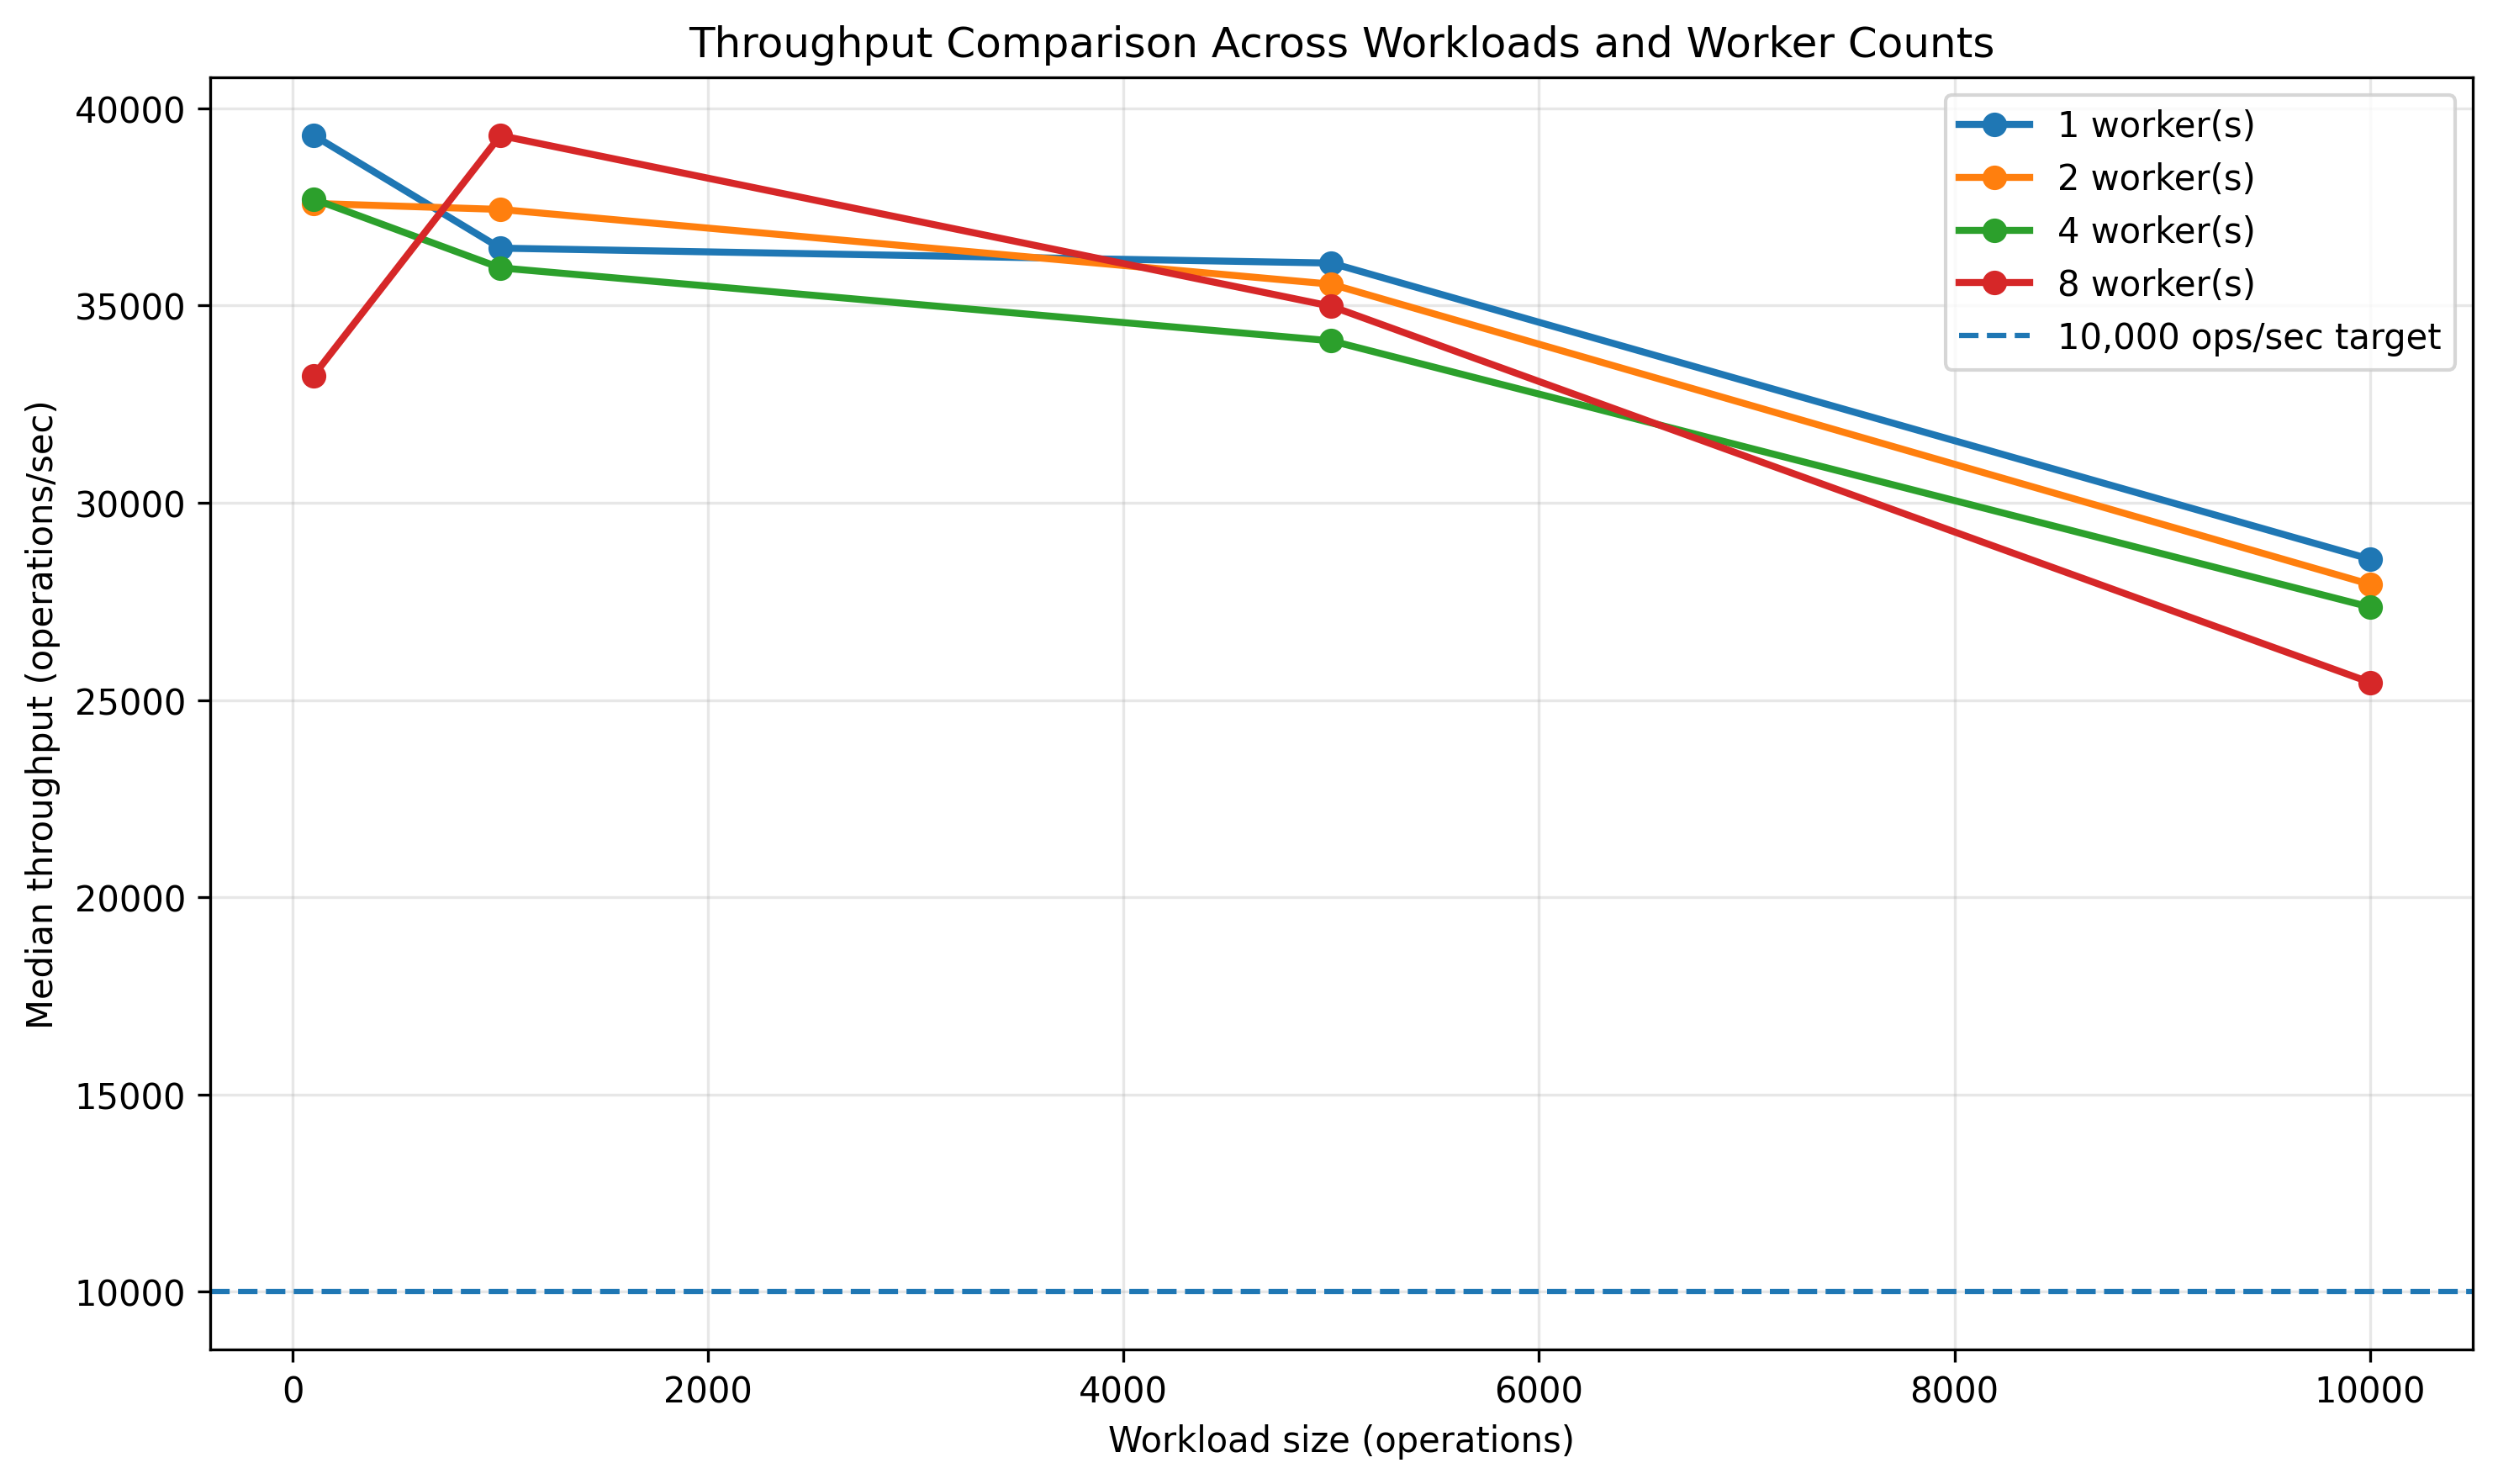


Figure_2_Latency_Percentiles.png


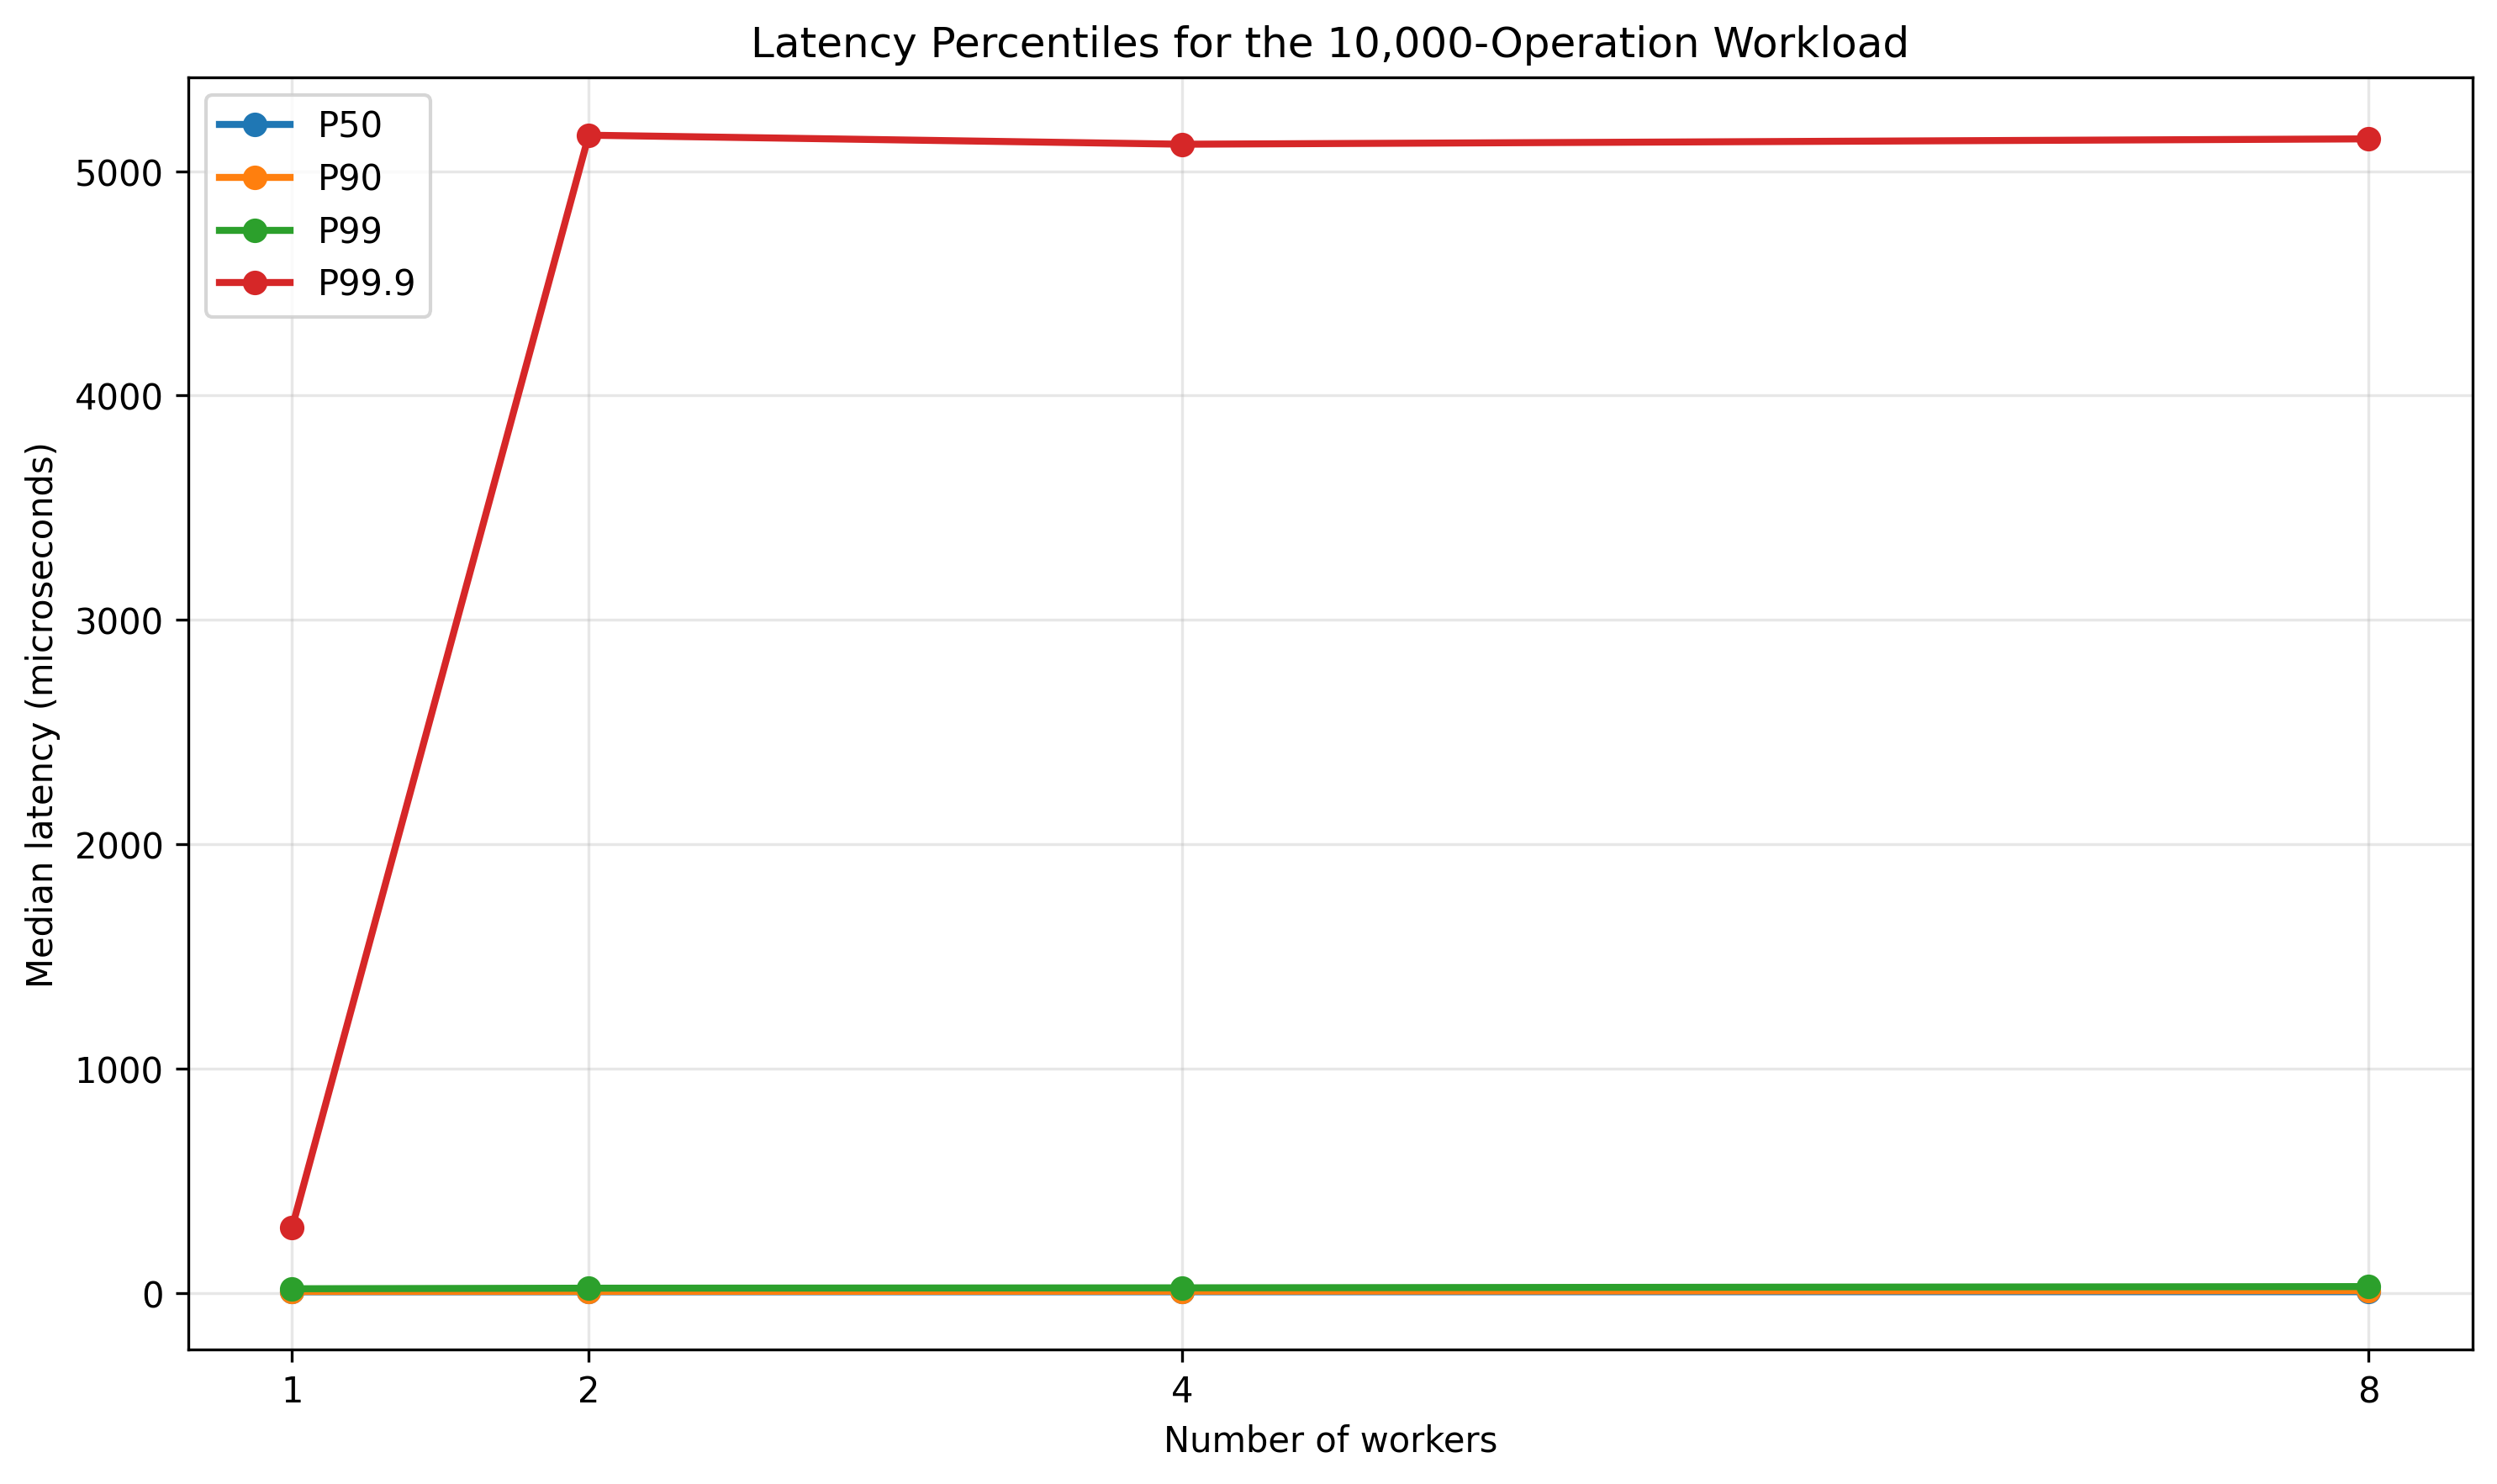


Figure_3_Throughput_Stability.png


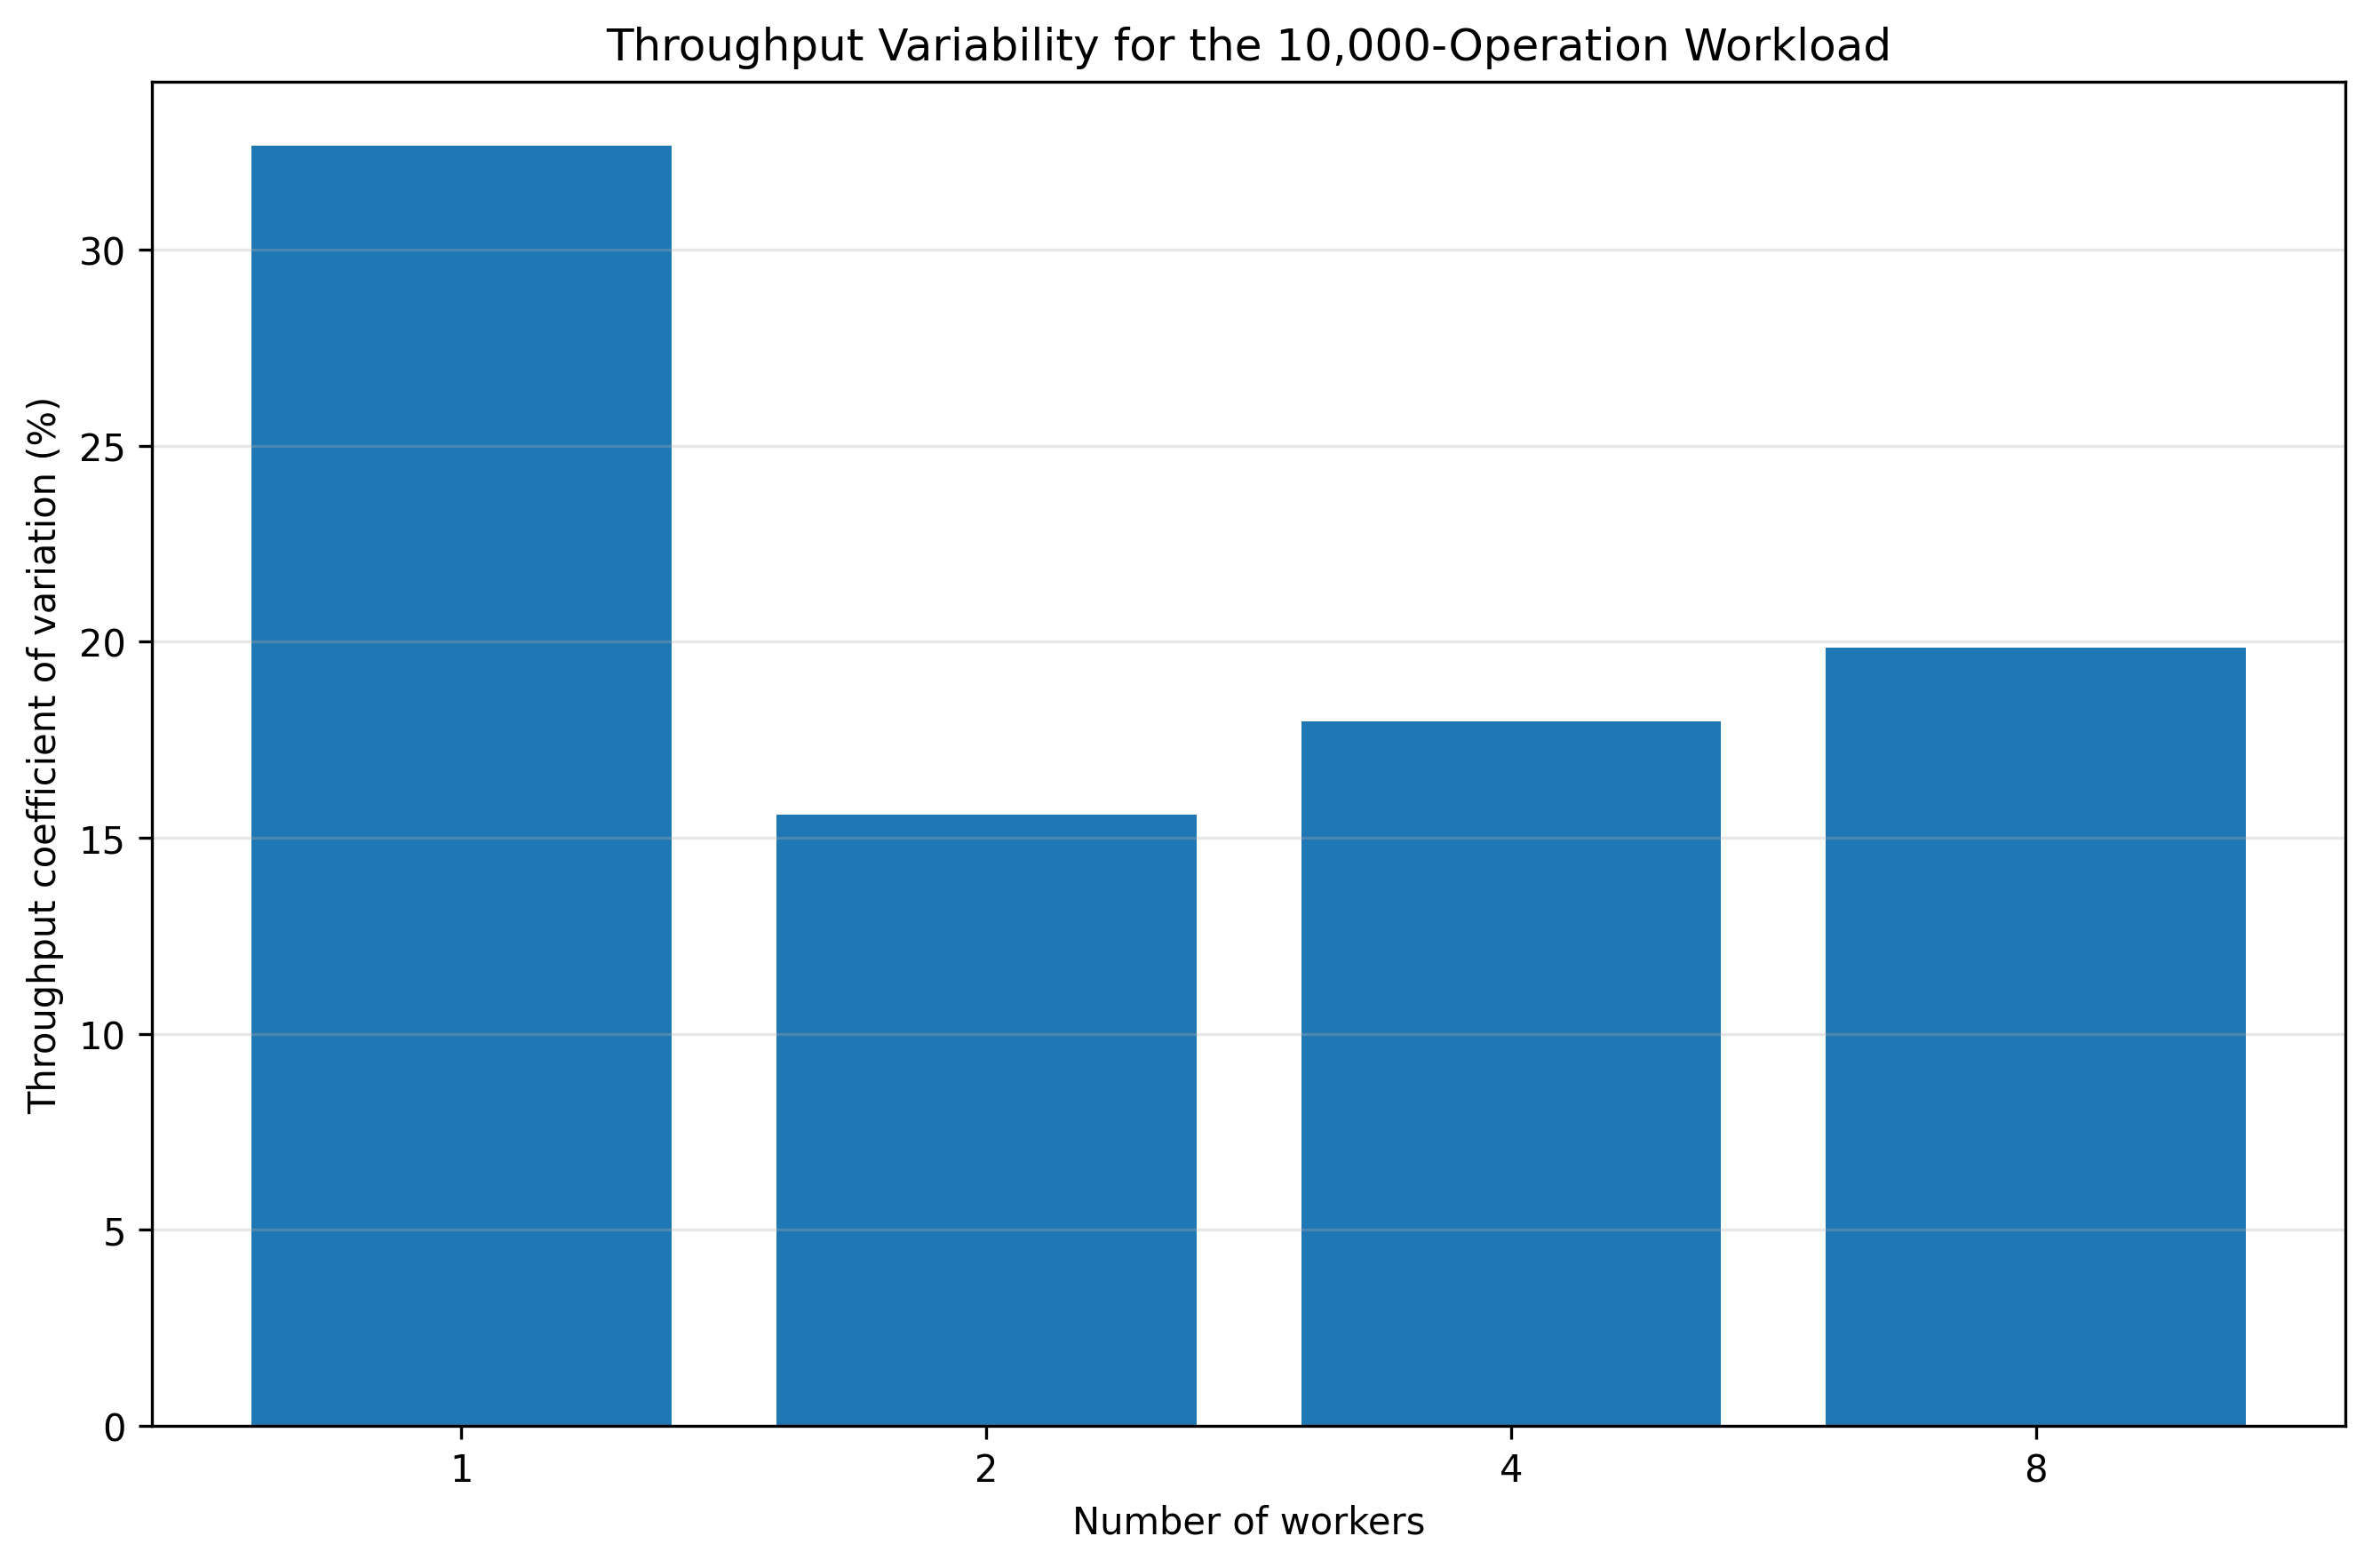


Figure_4_Target_Attainment.png


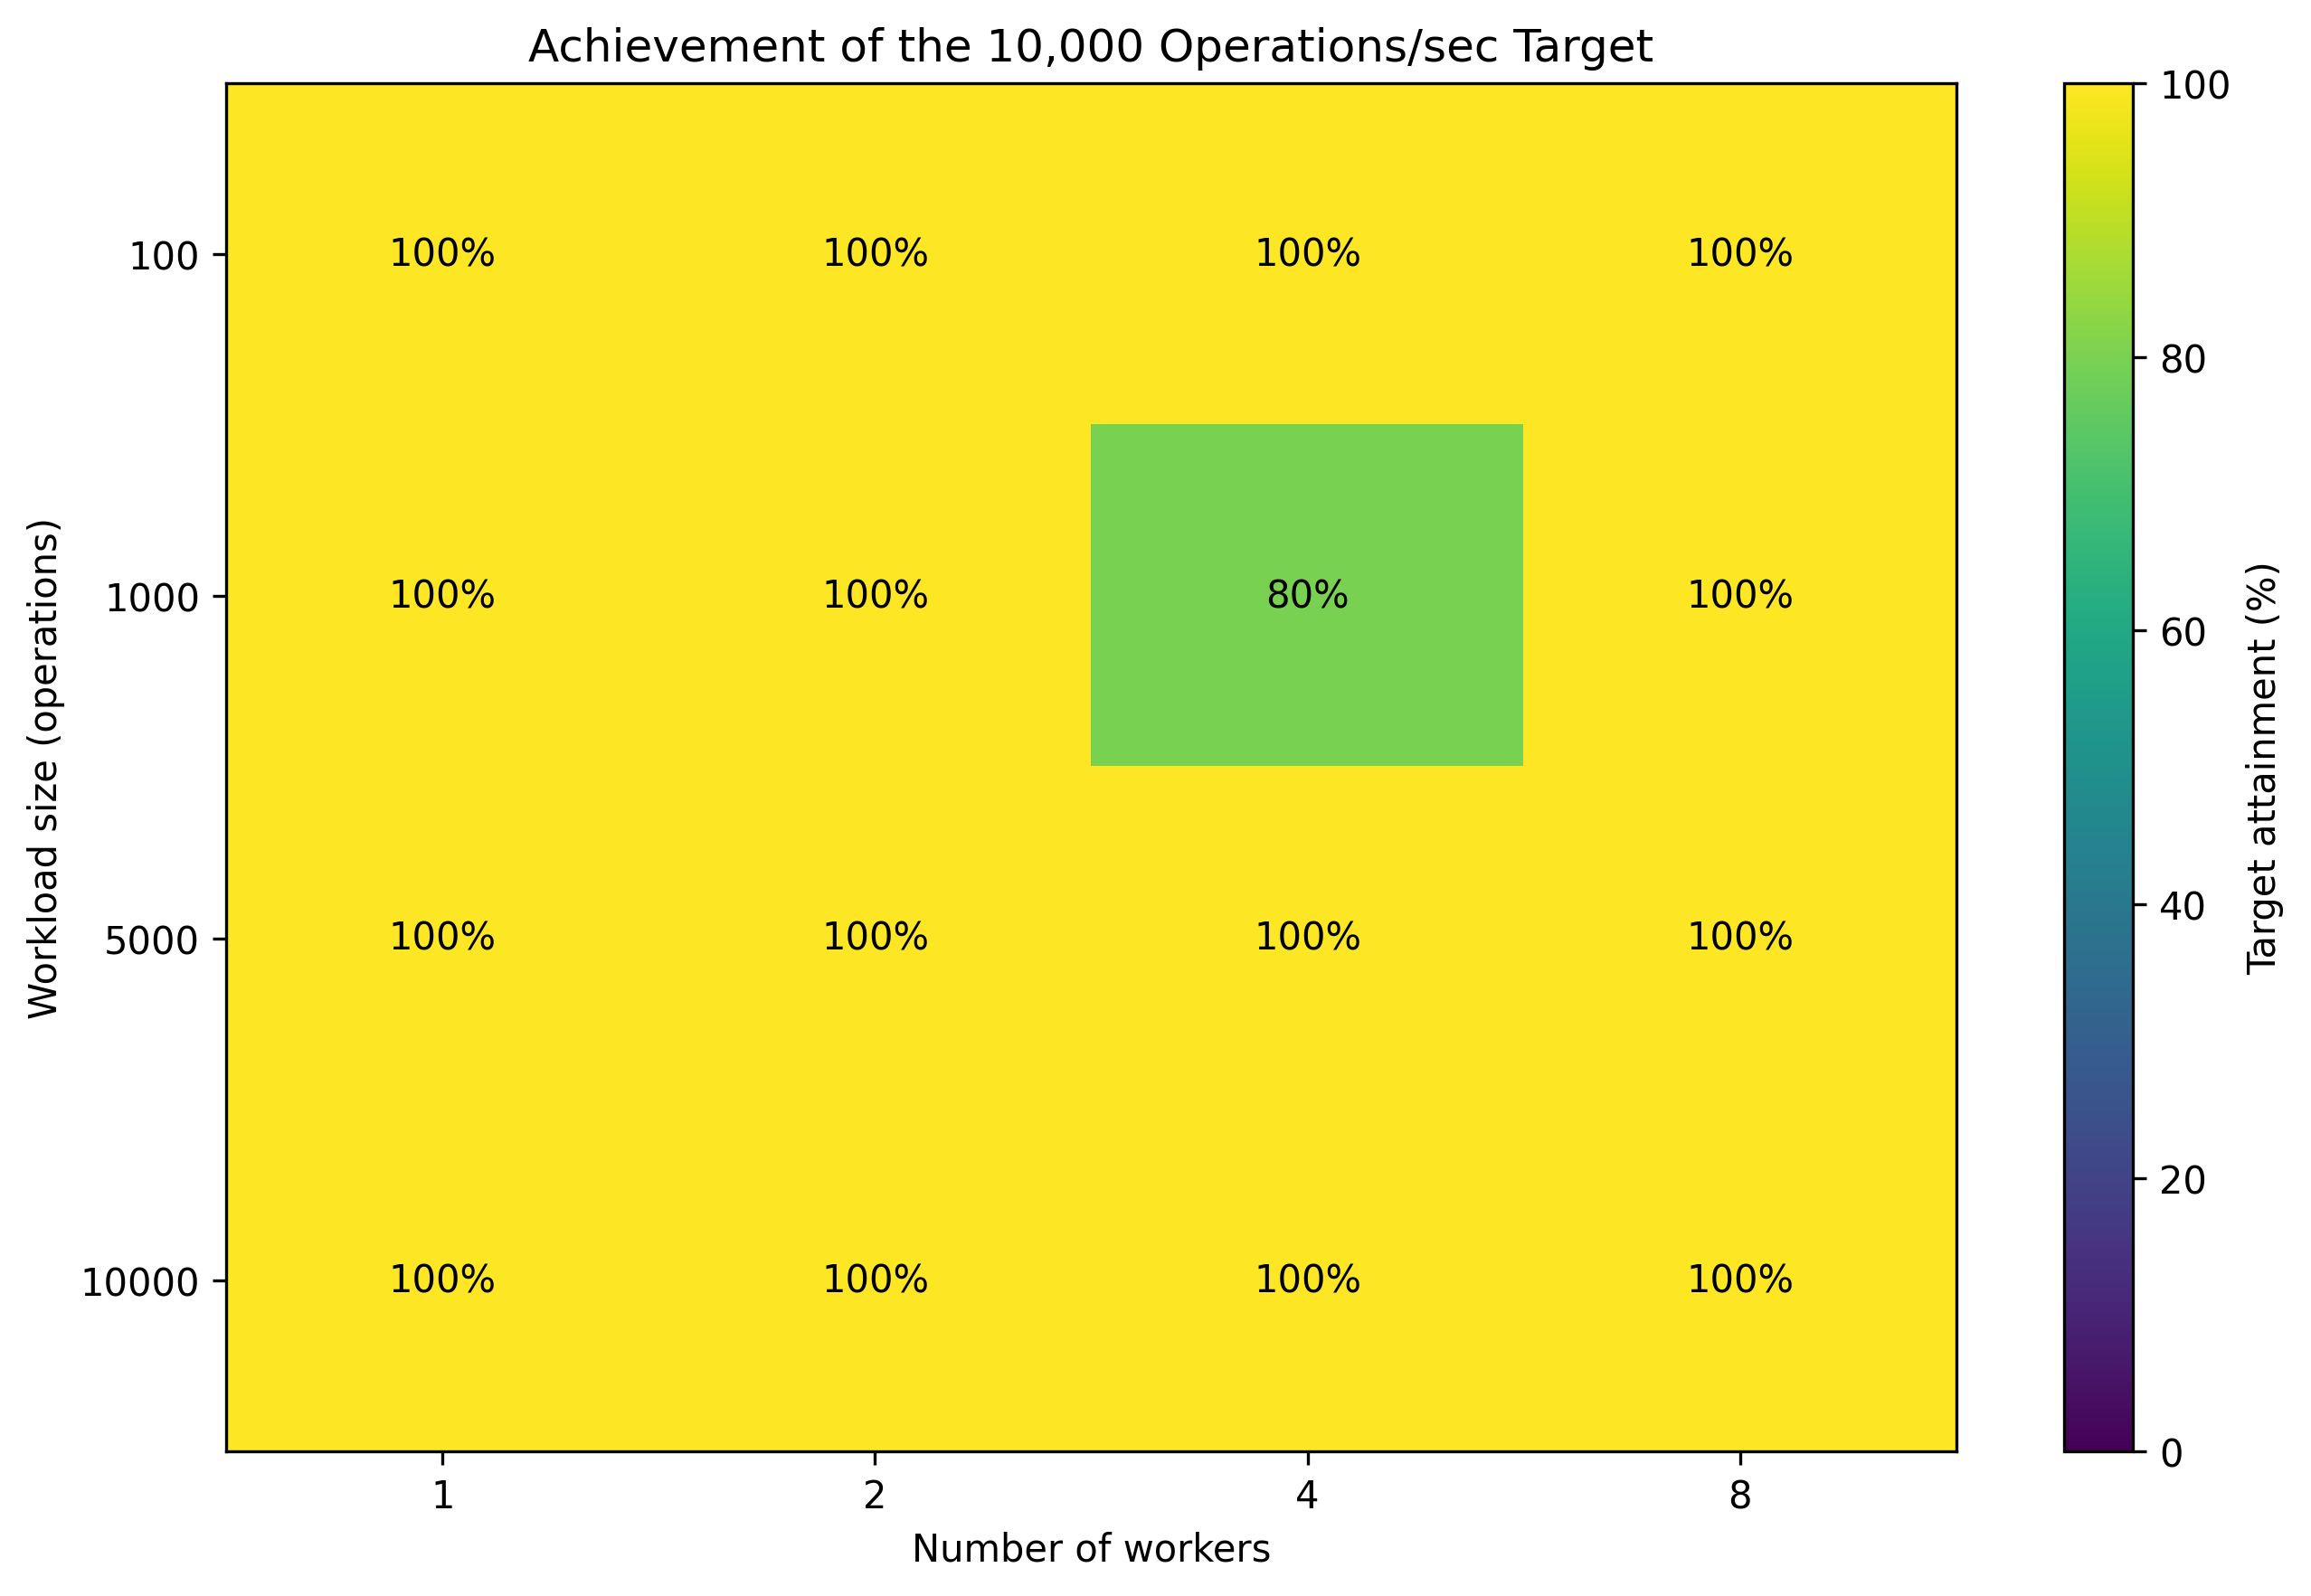


[PASS] Figure display completed.


In [30]:
from pathlib import Path
from IPython.display import display, Image

project = Path("/content/MSC501-M5-Distributed-Processing")
figures_dir = project / "diagrams"

figures = [
    "Figure_1_Throughput_Comparison.png",
    "Figure_2_Latency_Percentiles.png",
    "Figure_3_Throughput_Stability.png",
    "Figure_4_Target_Attainment.png"
]

print("=" * 75)
print("STAGE 10.2A: PERFORMANCE FIGURE DISPLAY")
print("=" * 75)

for filename in figures:
    filepath = figures_dir / filename

    if not filepath.exists():
        print(f"[NOT FOUND] {filename}")
        continue

    print(f"\n{filename}")
    display(Image(filename=str(filepath)))

print("\n[PASS] Figure display completed.")

In [31]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

project = Path("/content/MSC501-M5-Distributed-Processing")
figures_dir = project / "diagrams"
figures_dir.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("STAGE 10.3: SYSTEM ARCHITECTURE AND SEQUENCE DIAGRAMS")
print("=" * 75)

# --------------------------------------------------
# FIGURE 5: SYSTEM ARCHITECTURE
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 9))
ax.set_xlim(0, 15)
ax.set_ylim(0, 10)
ax.axis("off")

def add_box(ax, x, y, width, height, title, details=""):
    box = FancyBboxPatch(
        (x, y), width, height,
        boxstyle="round,pad=0.08",
        linewidth=1.5,
        edgecolor="black",
        facecolor="white"
    )
    ax.add_patch(box)
    ax.text(
        x + width / 2,
        y + height * 0.68,
        title,
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold"
    )
    if details:
        ax.text(
            x + width / 2,
            y + height * 0.32,
            details,
            ha="center",
            va="center",
            fontsize=8
        )

def add_arrow(ax, start, end, label=None):
    arrow = FancyArrowPatch(
        start, end,
        arrowstyle="->",
        mutation_scale=15,
        linewidth=1.4,
        color="black"
    )
    ax.add_patch(arrow)

    if label:
        ax.text(
            (start[0] + end[0]) / 2,
            (start[1] + end[1]) / 2 + 0.15,
            label,
            ha="center",
            fontsize=8
        )

ax.text(
    7.5, 9.55,
    "FAULT-TOLERANT DISTRIBUTED PROCESSING SUBSYSTEM",
    ha="center",
    fontsize=15,
    fontweight="bold"
)

# Main processing flow
add_box(ax, 0.5, 7.2, 2.3, 1.1, "Request Producer",
        "Synthetic workload")
add_box(ax, 3.4, 7.2, 2.3, 1.1, "Input Validation",
        "IDs, payload, timestamp")
add_box(ax, 6.3, 7.2, 2.3, 1.1, "Bounded Queue",
        "Capacity control")
add_box(ax, 9.2, 7.2, 2.3, 1.1, "Concurrent Workers",
        "ThreadPoolExecutor")
add_box(ax, 12.1, 7.2, 2.3, 1.1, "Processing Engine",
        "Arithmetic operations")

add_arrow(ax, (2.8, 7.75), (3.4, 7.75))
add_arrow(ax, (5.7, 7.75), (6.3, 7.75))
add_arrow(ax, (8.6, 7.75), (9.2, 7.75))
add_arrow(ax, (11.5, 7.75), (12.1, 7.75))

# Reliability components
add_box(ax, 3.0, 4.6, 3.0, 1.25, "Fault Injection",
        "Simulated message loss")
add_box(ax, 7.0, 4.6, 3.0, 1.25, "Retry and Recovery",
        "Seeded retries")
add_box(ax, 11.0, 4.6, 3.0, 1.25, "Transaction Manager",
        "SQLite, WAL, idempotency")

add_arrow(ax, (13.2, 7.2), (12.5, 5.85))
add_arrow(ax, (11.0, 5.2), (10.0, 5.2))
add_arrow(ax, (7.0, 5.2), (6.0, 5.2))
add_arrow(ax, (4.5, 5.85), (4.5, 7.2), "Retry path")

# Observability
add_box(ax, 3.0, 1.8, 4.0, 1.25, "Structured Telemetry",
        "JSONL, UTC timestamps, trace IDs")
add_box(ax, 8.0, 1.8, 4.0, 1.25, "Performance Monitoring",
        "Throughput, P50, P90, P99, P99.9")

add_arrow(ax, (8.5, 4.6), (6.0, 3.05))
add_arrow(ax, (12.0, 4.6), (7.0, 2.45))
add_arrow(ax, (7.0, 2.45), (8.0, 2.45))

ax.text(
    7.5, 0.75,
    "Local concurrent simulation with durable transaction state and simulated message loss",
    ha="center",
    fontsize=9,
    style="italic"
)

plt.tight_layout()

plt.savefig(
    figures_dir / "Figure_5_System_Architecture.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# --------------------------------------------------
# FIGURE 6: PROCESSING SEQUENCE
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 9))
ax.set_xlim(0, 15)
ax.set_ylim(0, 12)
ax.axis("off")

ax.text(
    7.5, 11.5,
    "FAULT-TOLERANT REQUEST PROCESSING SEQUENCE",
    ha="center",
    fontsize=15,
    fontweight="bold"
)

participants = [
    ("Producer", 1.5),
    ("Validator", 4.0),
    ("Queue / Worker", 6.5),
    ("Fault Handler", 9.0),
    ("SQLite Manager", 11.5),
    ("Telemetry", 13.8)
]

for name, x in participants:
    ax.text(
        x, 10.7, name,
        ha="center",
        fontsize=9,
        fontweight="bold"
    )
    ax.plot([x, x], [1.0, 10.4], linestyle="--",
            linewidth=1, color="black")

def sequence_arrow(x1, y1, x2, y2, label):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(arrowstyle="->", linewidth=1.2)
    )
    ax.text(
        (x1 + x2) / 2,
        y1 + 0.12,
        label,
        ha="center",
        fontsize=7.5
    )

sequence_arrow(1.5, 9.8, 4.0, 9.8, "Submit request")
sequence_arrow(4.0, 9.1, 6.5, 9.1, "Validated request")
sequence_arrow(6.5, 8.4, 11.5, 8.4, "Register transaction")
sequence_arrow(11.5, 7.7, 9.0, 7.7, "Pending state")
sequence_arrow(9.0, 7.0, 6.5, 7.0, "Attempt delivery")

# Simulated packet loss and retry
ax.text(
    7.75, 6.35,
    "ALT: Message dropped",
    ha="center",
    fontsize=8,
    fontweight="bold"
)

sequence_arrow(9.0, 5.9, 9.0, 5.4, "Retry")
sequence_arrow(9.0, 5.4, 6.5, 5.4, "Redelivery")

sequence_arrow(6.5, 4.7, 11.5, 4.7, "Commit result")
sequence_arrow(11.5, 4.0, 13.8, 4.0, "Record event")
sequence_arrow(6.5, 3.3, 13.8, 3.3, "Processing telemetry")
sequence_arrow(11.5, 2.6, 1.5, 2.6, "Return result")

ax.text(
    7.5, 1.45,
    "Duplicate requests are recognised through durable transaction identity and idempotent registration.",
    ha="center",
    fontsize=8,
    style="italic"
)

plt.tight_layout()

plt.savefig(
    figures_dir / "Figure_6_Processing_Sequence.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()


# --------------------------------------------------
# VERIFY OUTPUTS
# --------------------------------------------------

print("\nGENERATED SYSTEM DIAGRAMS")

for filename in [
    "Figure_5_System_Architecture.png",
    "Figure_6_Processing_Sequence.png"
]:
    path = figures_dir / filename
    print(f"[PASS] {filename} | {path.stat().st_size:,} bytes")

print("\n[PASS] System architecture and sequence diagrams generated.")

STAGE 10.3: SYSTEM ARCHITECTURE AND SEQUENCE DIAGRAMS

GENERATED SYSTEM DIAGRAMS
[PASS] Figure_5_System_Architecture.png | 321,524 bytes
[PASS] Figure_6_Processing_Sequence.png | 210,865 bytes

[PASS] System architecture and sequence diagrams generated.



Figure_5_System_Architecture.png


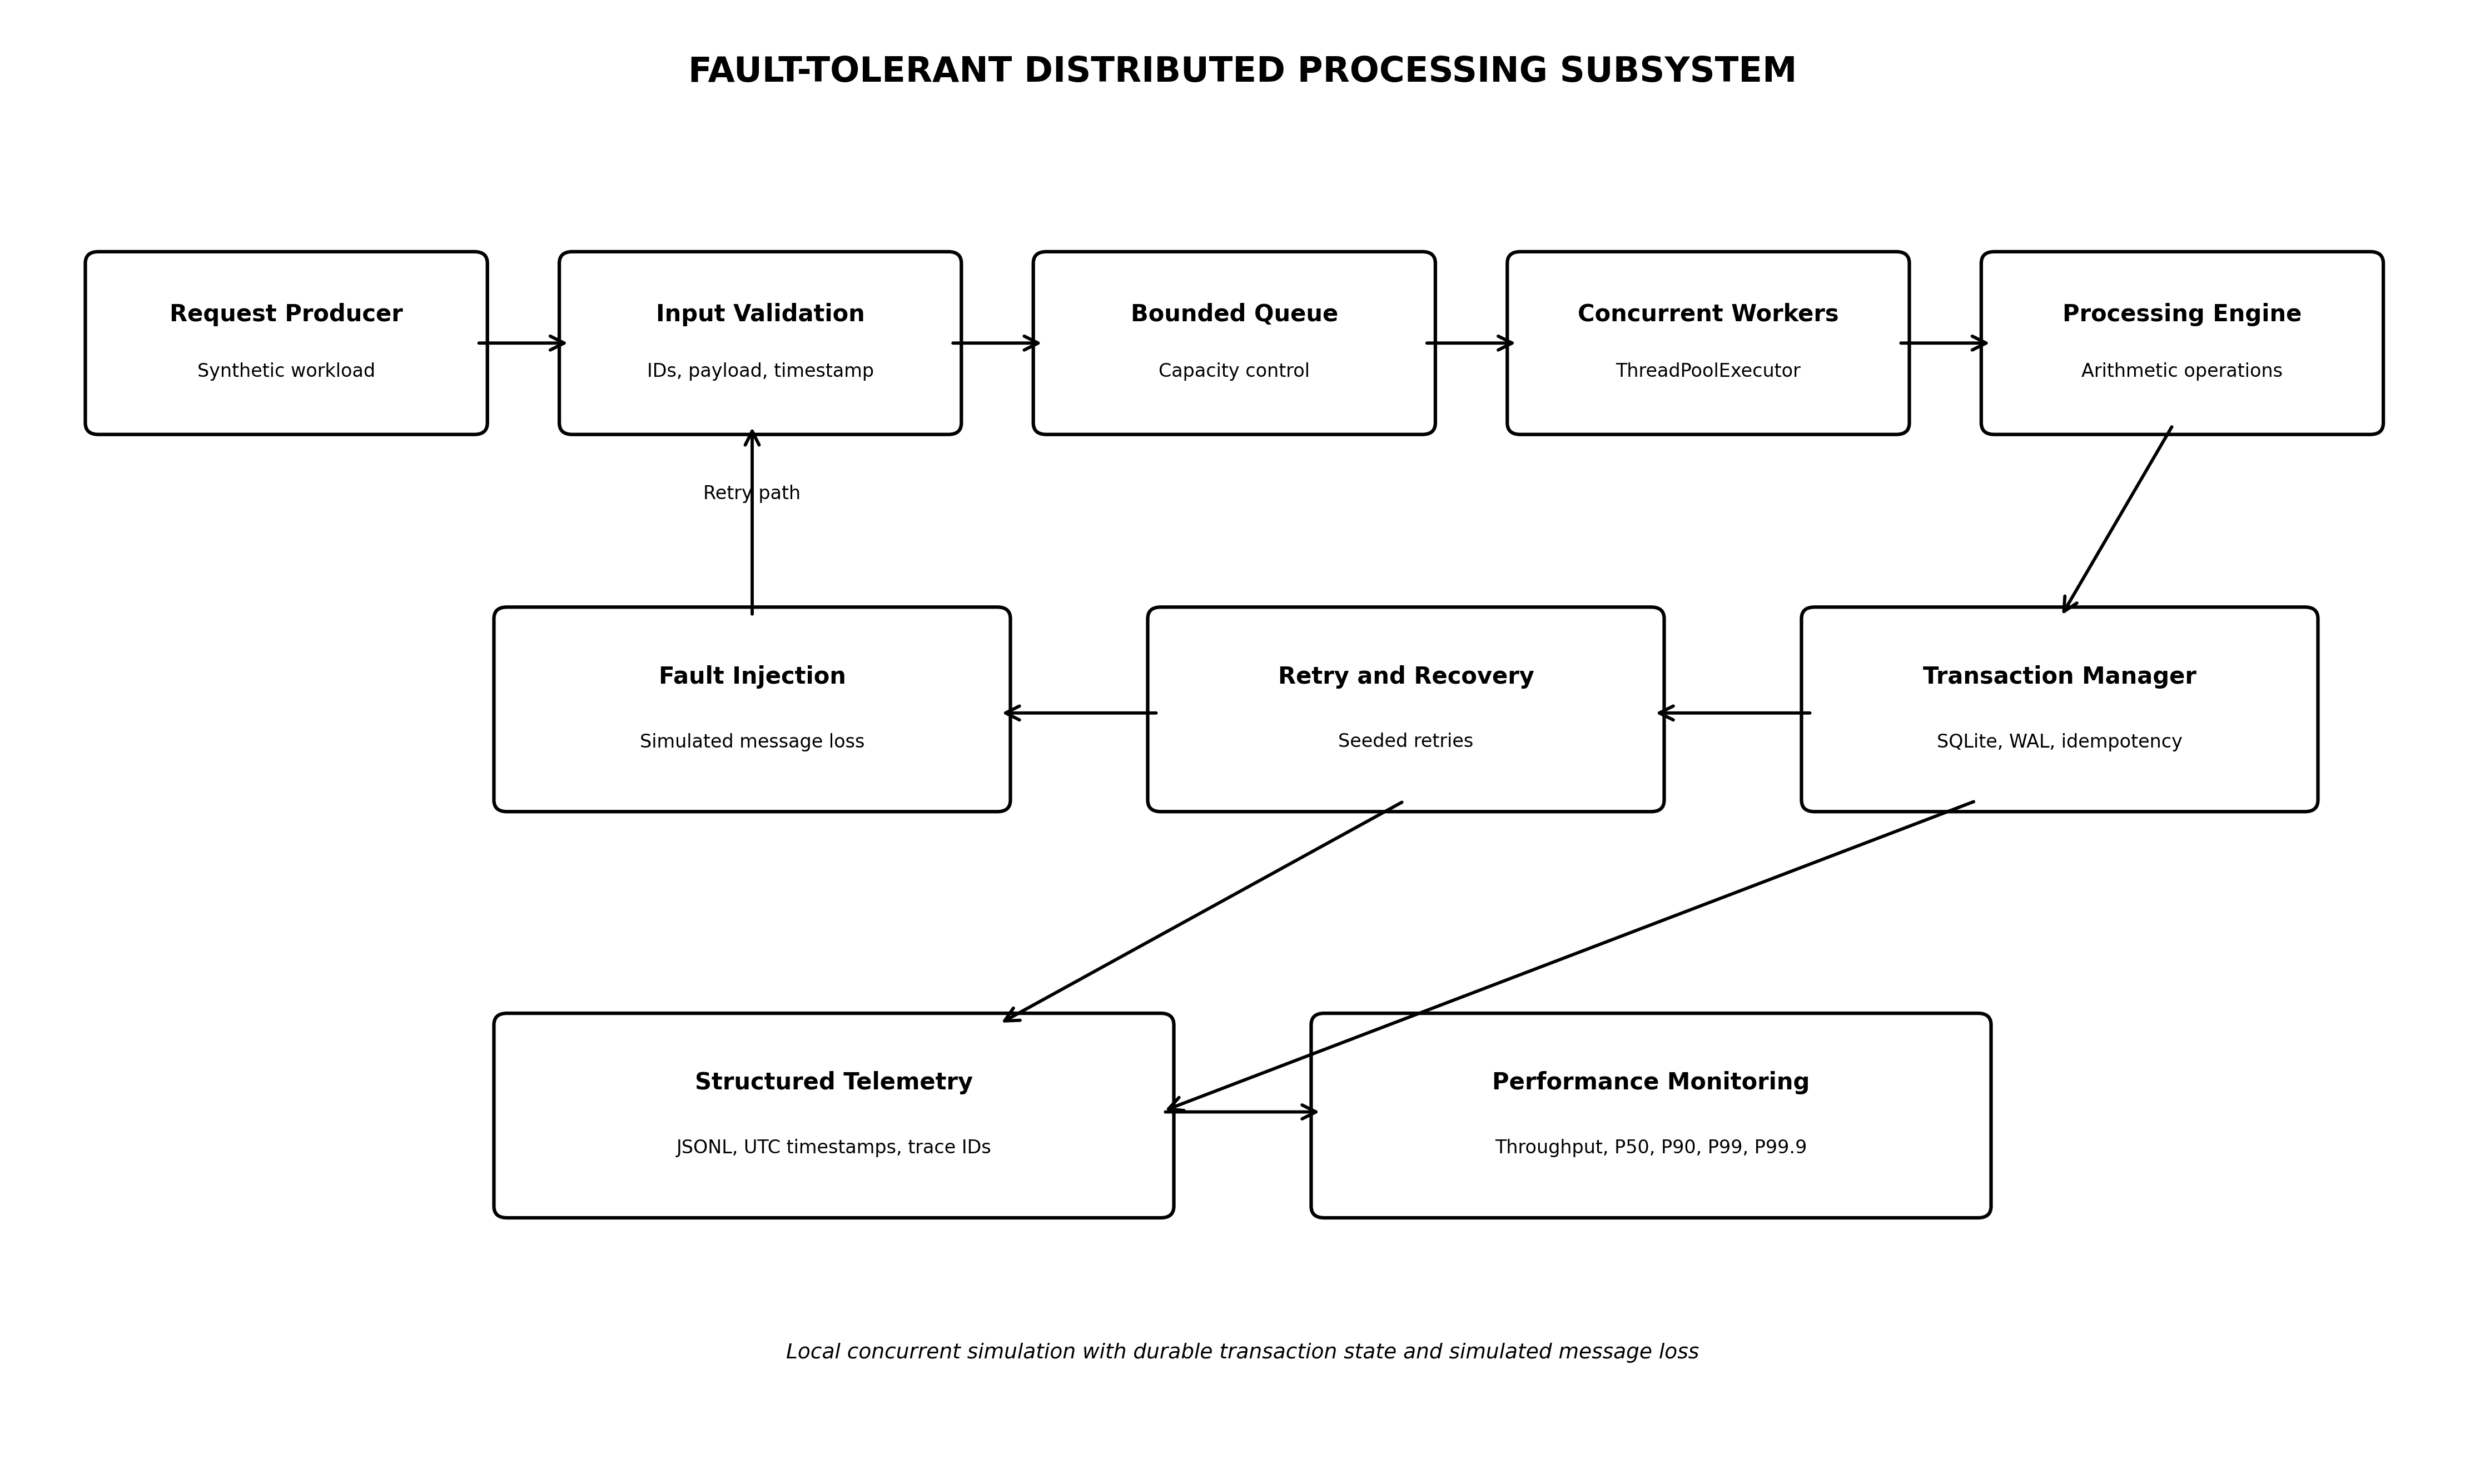


Figure_6_Processing_Sequence.png


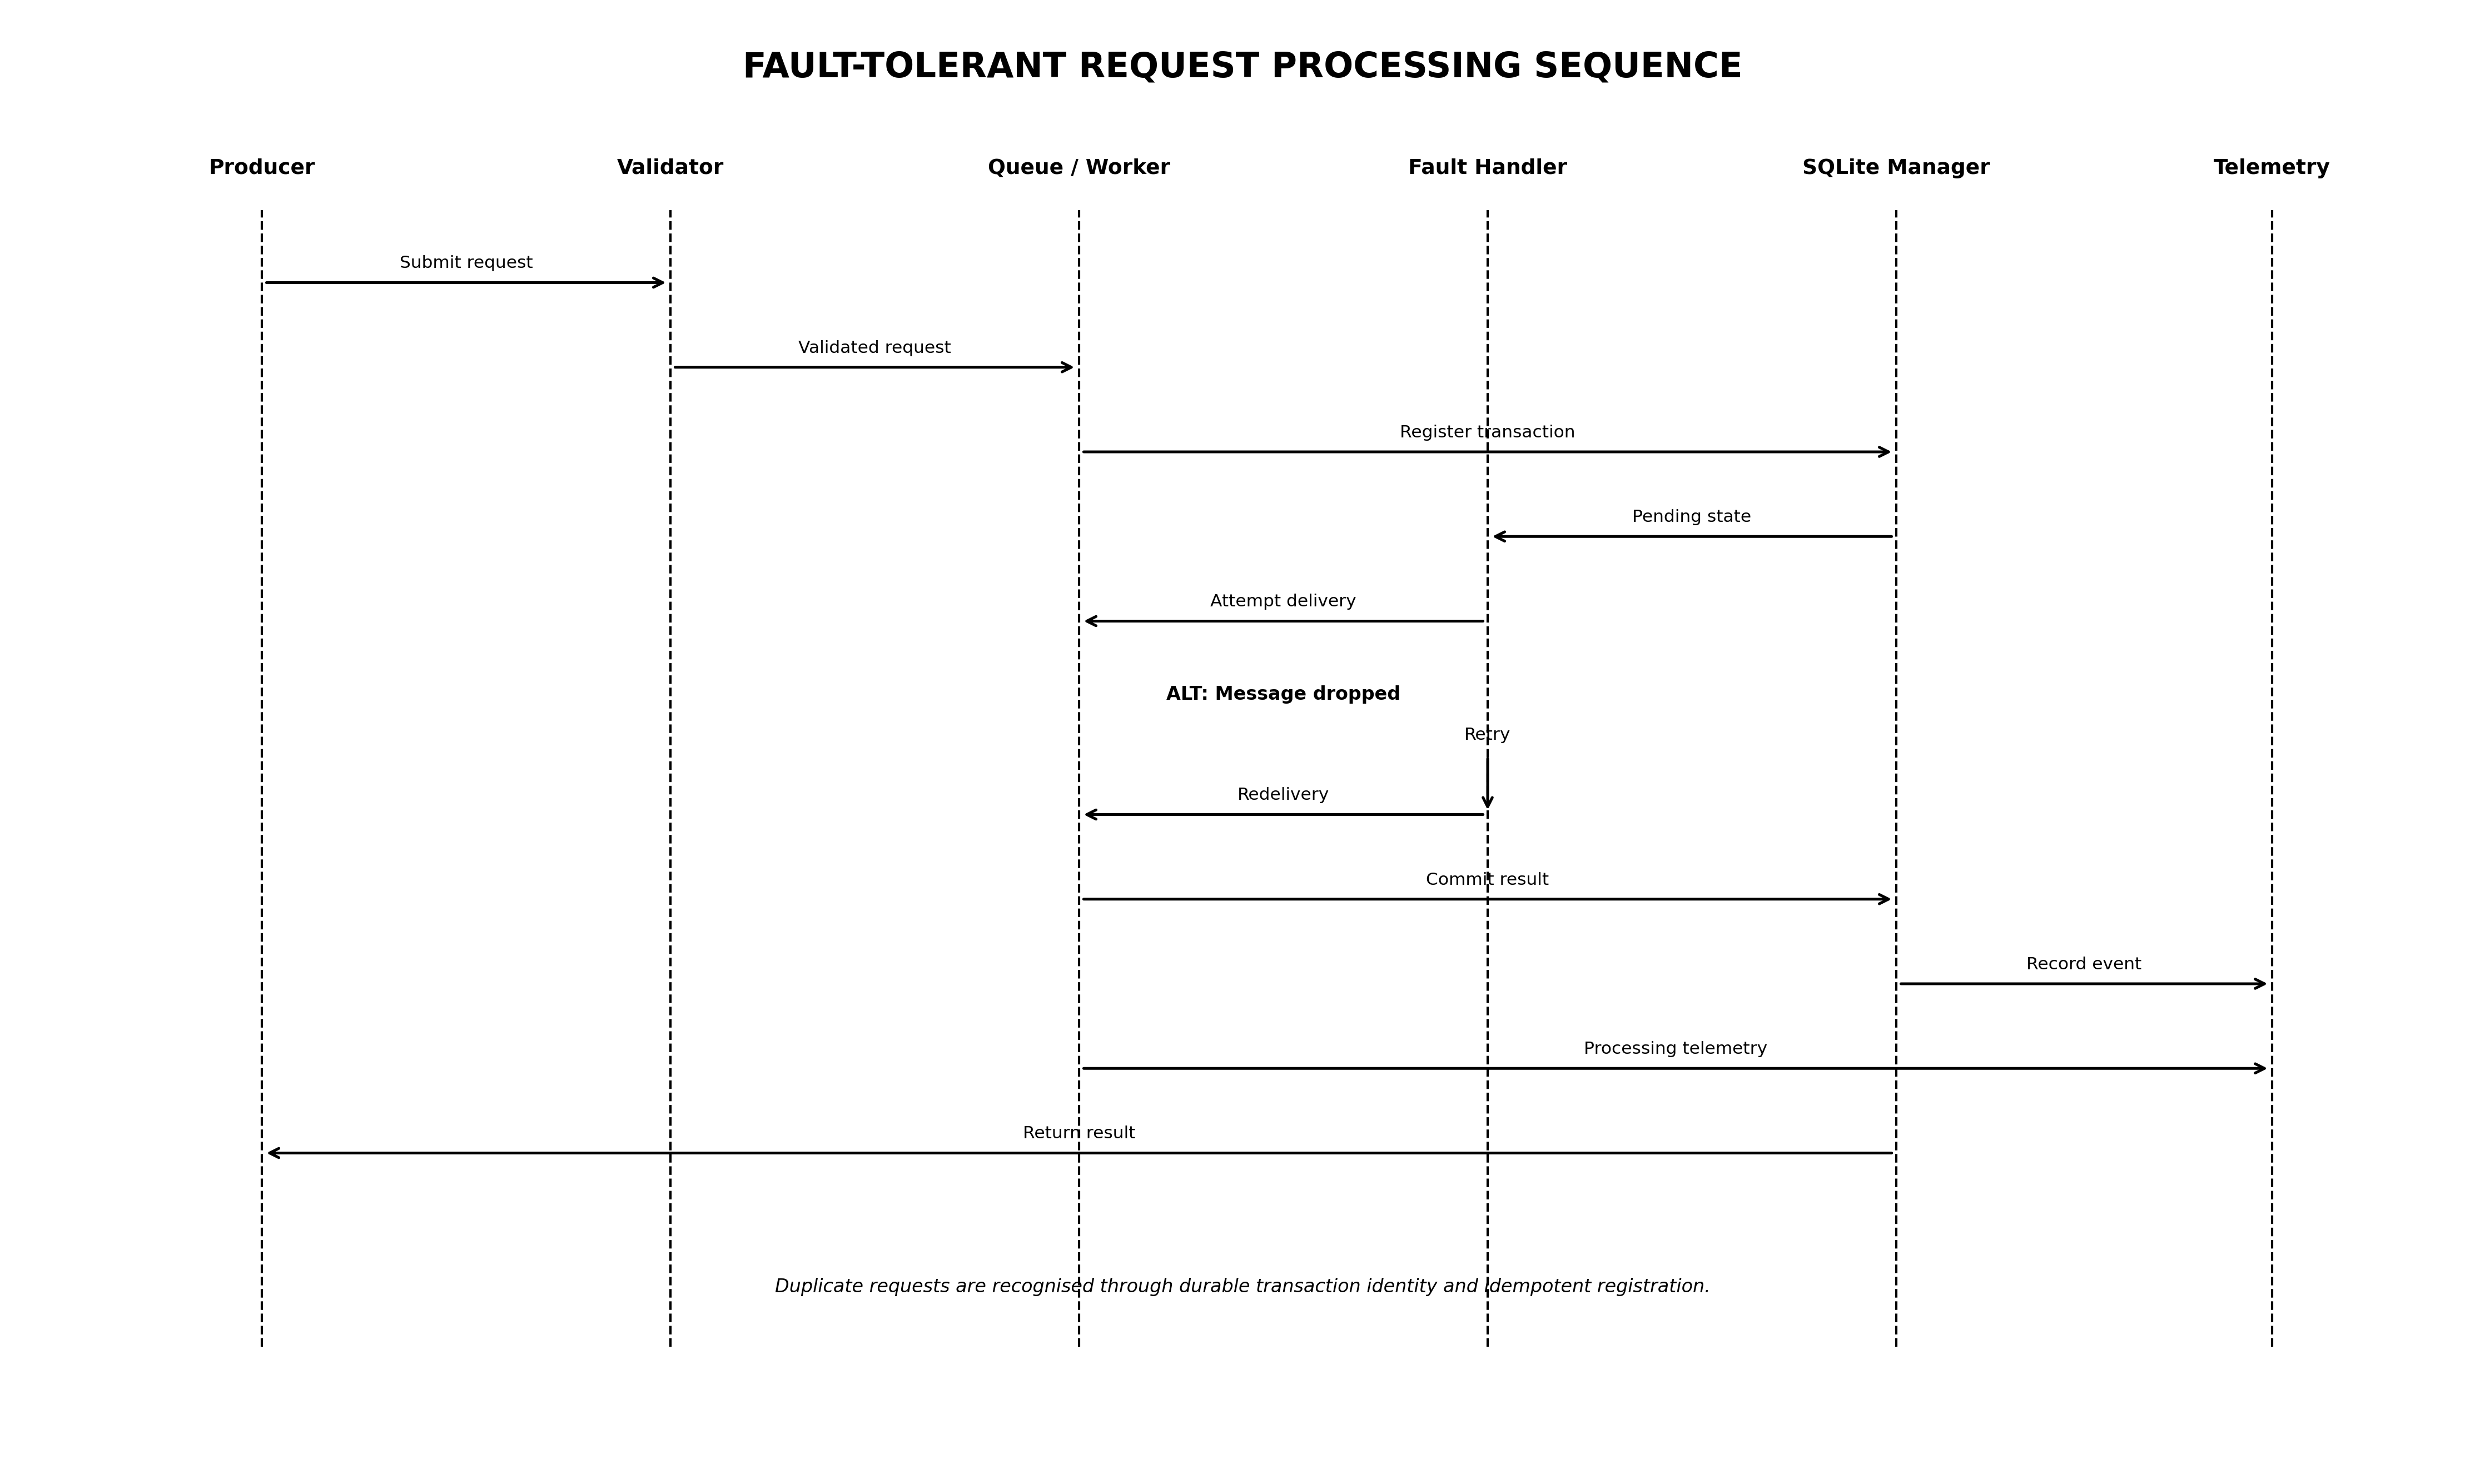


[PASS] Both system diagrams displayed.


In [32]:
from pathlib import Path
from IPython.display import display, Image

project = Path("/content/MSC501-M5-Distributed-Processing")
figures_dir = project / "diagrams"

figures = [
    "Figure_5_System_Architecture.png",
    "Figure_6_Processing_Sequence.png"
]

for filename in figures:
    path = figures_dir / filename

    print("\n" + "=" * 75)
    print(filename)
    print("=" * 75)

    if not path.exists():
        raise FileNotFoundError(filename)

    display(Image(filename=str(path)))

print("\n[PASS] Both system diagrams displayed.")

In [33]:
from pathlib import Path
import pandas as pd
import json

project = Path("/content/MSC501-M5-Distributed-Processing")
results_dir = project / "results"

print("=" * 75)
print("STAGE 10.4: RELIABILITY DATA VERIFICATION")
print("=" * 75)

print("\nAVAILABLE RESULT FILES")
for path in sorted(results_dir.glob("*")):
    if path.is_file():
        print(f"{path.name:<40} {path.stat().st_size:,} bytes")

print("\nCSV DATA SUMMARY")
for path in sorted(results_dir.glob("*.csv")):
    try:
        df = pd.read_csv(path)
        print(f"\n{path.name}")
        print("Rows:", len(df))
        print("Columns:", list(df.columns))
    except Exception as exc:
        print(f"[READ ERROR] {path.name}: {exc}")

telemetry_file = results_dir / "telemetry.jsonl"

if telemetry_file.exists():
    print("\nTELEMETRY SUMMARY")
    records = []

    with telemetry_file.open("r", encoding="utf-8") as file:
        for line in file:
            if line.strip():
                records.append(json.loads(line))

    print("Total telemetry records:", len(records))

    if records:
        telemetry_df = pd.DataFrame(records)
        print("Available fields:", list(telemetry_df.columns))

        if "status" in telemetry_df.columns:
            print("\nStatus distribution:")
            print(telemetry_df["status"].value_counts().to_string())

        if "status_code" in telemetry_df.columns:
            print("\nStatus code distribution:")
            print(telemetry_df["status_code"].value_counts().to_string())
else:
    print("\nTelemetry JSONL file not found.")

print("\n[PASS] Reliability data inspection completed.")

STAGE 10.4: RELIABILITY DATA VERIFICATION

AVAILABLE RESULT FILES
stage6_faults.db                         77,824 bytes
stage7_telemetry.jsonl                   74,904 bytes
stage7_transactions.db                   77,824 bytes
stage8_performance_benchmark.csv         2,835 bytes
stage8_repeated_raw.csv                  13,576 bytes
stage8_repeated_summary.csv              2,487 bytes
stage8_stability_analysis.csv            2,631 bytes
transactions.db                          16,384 bytes

CSV DATA SUMMARY

stage8_performance_benchmark.csv
Rows: 16
Columns: ['operations', 'workers', 'completed', 'successful', 'failed', 'elapsed_seconds', 'throughput_ops_sec', 'mean_latency_us', 'p50_latency_us', 'p90_latency_us', 'p99_latency_us', 'p99_9_latency_us', 'theoretical_capacity_ops_sec', 'capacity_ratio']

stage8_repeated_raw.csv
Rows: 80
Columns: ['operations', 'workers', 'completed', 'successful', 'failed', 'elapsed_seconds', 'throughput_ops_sec', 'mean_latency_us', 'p50_latency_us', 'p90

In [34]:
from pathlib import Path
import pandas as pd
import sqlite3
import json

project = Path("/content/MSC501-M5-Distributed-Processing")
results_dir = project / "results"

print("=" * 75)
print("STAGE 10.4A: TELEMETRY AND TRANSACTION VERIFICATION")
print("=" * 75)

# Inspect the actual Stage 7 telemetry file
telemetry_file = results_dir / "stage7_telemetry.jsonl"

if not telemetry_file.exists():
    raise FileNotFoundError(telemetry_file)

records = []

with telemetry_file.open("r", encoding="utf-8") as file:
    for line in file:
        if line.strip():
            records.append(json.loads(line))

telemetry_df = pd.DataFrame(records)

print("\nTELEMETRY SUMMARY")
print("Total events:", len(telemetry_df))
print("Fields:", list(telemetry_df.columns))

for column in ["status", "status_code"]:
    if column in telemetry_df.columns:
        print(f"\n{column.upper()} DISTRIBUTION")
        print(telemetry_df[column].value_counts(dropna=False).to_string())

if "request_id" in telemetry_df.columns:
    print("\nUnique requests:", telemetry_df["request_id"].nunique())

# Inspect SQLite transaction databases
for database_name in ["stage6_faults.db", "stage7_transactions.db"]:
    database_path = results_dir / database_name

    print(f"\nDATABASE: {database_name}")

    if not database_path.exists():
        print("[NOT FOUND]")
        continue

    connection = sqlite3.connect(database_path)

    tables = pd.read_sql_query(
        "SELECT name FROM sqlite_master WHERE type='table'",
        connection
    )

    print("Tables:", tables["name"].tolist())

    for table_name in tables["name"]:
        safe_name = table_name.replace('"', '""')
        table_df = pd.read_sql_query(
            f'SELECT * FROM "{safe_name}"',
            connection
        )

        print(f"\nTable: {table_name}")
        print("Records:", len(table_df))
        print("Columns:", list(table_df.columns))

        if "status" in table_df.columns:
            print("Status distribution:")
            print(table_df["status"].value_counts(dropna=False).to_string())

    connection.close()

print("\n[PASS] Telemetry and transaction inspection completed.")

STAGE 10.4A: TELEMETRY AND TRANSACTION VERIFICATION

TELEMETRY SUMMARY
Total events: 252
Fields: ['timestamp', 'level', 'message', 'request_id', 'trace_id', 'status_code', 'status', 'latency_us', 'attempts', 'worker']

STATUS DISTRIBUTION
status
DELIVERED    100
SUCCESS      100
DROPPED       52

STATUS_CODE DISTRIBUTION
status_code
202    100
200    100
503     52

Unique requests: 100

DATABASE: stage6_faults.db
Tables: ['transactions']

Table: transactions
Records: 100
Columns: ['request_id', 'trace_id', 'payload', 'payload_hash', 'status', 'result', 'created_at', 'committed_at']
Status distribution:
status
SUCCESS    100

DATABASE: stage7_transactions.db
Tables: ['transactions']

Table: transactions
Records: 100
Columns: ['request_id', 'trace_id', 'payload', 'payload_hash', 'status', 'result', 'created_at', 'committed_at']
Status distribution:
status
SUCCESS    100

[PASS] Telemetry and transaction inspection completed.


STAGE 10.5: RELIABILITY FIGURE GENERATION

VERIFIED RELIABILITY METRICS
Unique requests: 100
Transmission attempts: 152
Delivered messages: 100
Dropped messages: 52
Observed drop proportion: 34.21%
Successful processing events: 100
Committed transactions: 100
Failed transactions: 0
Pending transactions: 0


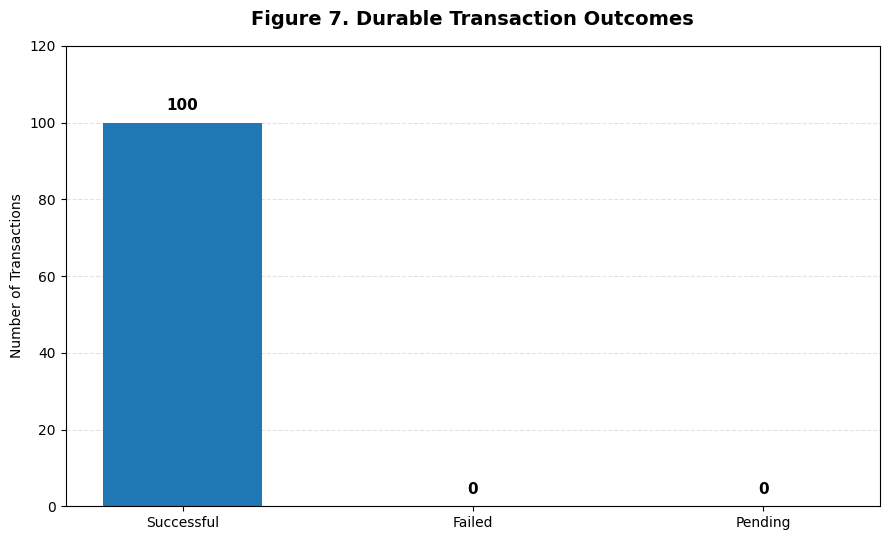

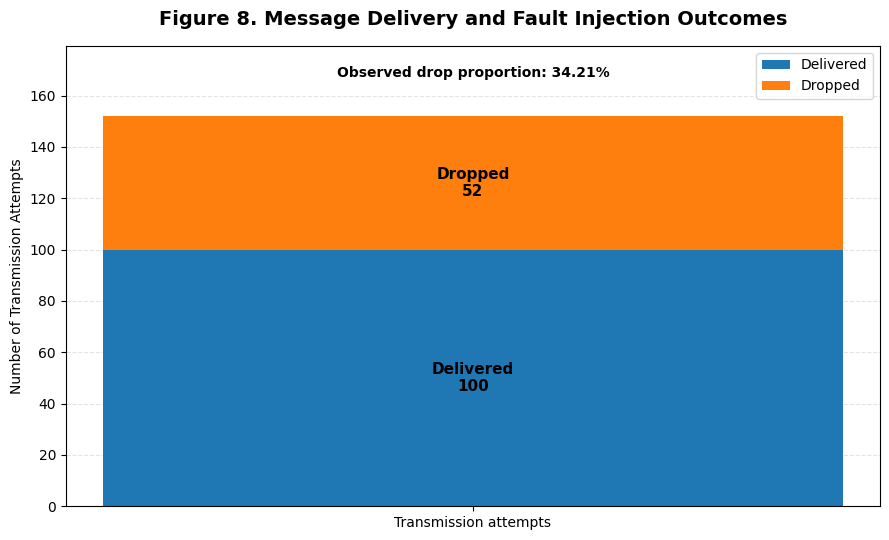


GENERATED FIGURES
PASS: Figure_7_Transaction_Outcomes.png (87,092 bytes)
PASS: Figure_8_Message_Delivery_Fault_Injection.png (139,590 bytes)

[PASS] Stage 10.5 reliability figures generated successfully.


In [35]:
from pathlib import Path
import pandas as pd
import sqlite3
import json
import matplotlib.pyplot as plt
import numpy as np

project = Path("/content/MSC501-M5-Distributed-Processing")
results_dir = project / "results"
diagrams_dir = project / "diagrams"
diagrams_dir.mkdir(parents=True, exist_ok=True)

print("=" * 75)
print("STAGE 10.5: RELIABILITY FIGURE GENERATION")
print("=" * 75)

# Load verified telemetry
telemetry_file = results_dir / "stage7_telemetry.jsonl"

with telemetry_file.open("r", encoding="utf-8") as file:
    records = [json.loads(line) for line in file if line.strip()]

telemetry_df = pd.DataFrame(records)

status_counts = telemetry_df["status"].value_counts()

delivered = int(status_counts.get("DELIVERED", 0))
dropped = int(status_counts.get("DROPPED", 0))
successful = int(status_counts.get("SUCCESS", 0))

transmission_attempts = delivered + dropped
observed_drop_rate = (
    dropped / transmission_attempts * 100
    if transmission_attempts else 0
)

# Read transaction outcomes from Stage 7 database
database_path = results_dir / "stage7_transactions.db"
connection = sqlite3.connect(database_path)

transactions_df = pd.read_sql_query(
    "SELECT request_id, status FROM transactions",
    connection
)

connection.close()

transaction_counts = transactions_df["status"].value_counts()

committed = int(transaction_counts.get("SUCCESS", 0))
failed = int(transaction_counts.get("FAILED", 0))
pending = int(transaction_counts.get("PENDING", 0))

# Verify consistency before plotting
assert len(transactions_df) == 100
assert committed == 100
assert delivered == 100
assert dropped == 52
assert successful == 100
assert transmission_attempts == 152

print("\nVERIFIED RELIABILITY METRICS")
print(f"Unique requests: {telemetry_df['request_id'].nunique()}")
print(f"Transmission attempts: {transmission_attempts}")
print(f"Delivered messages: {delivered}")
print(f"Dropped messages: {dropped}")
print(f"Observed drop proportion: {observed_drop_rate:.2f}%")
print(f"Successful processing events: {successful}")
print(f"Committed transactions: {committed}")
print(f"Failed transactions: {failed}")
print(f"Pending transactions: {pending}")

# ---------------------------------------------------------
# FIGURE 7: TRANSACTION OUTCOMES
# ---------------------------------------------------------
labels = ["Successful", "Failed", "Pending"]
values = [committed, failed, pending]

fig, ax = plt.subplots(figsize=(9, 5.5))

bars = ax.bar(labels, values, width=0.55)

ax.set_title(
    "Figure 7. Durable Transaction Outcomes",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_ylabel("Number of Transactions")
ax.set_ylim(0, max(values + [1]) * 1.20)
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

for bar, value in zip(bars, values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + max(values + [1]) * 0.025,
        f"{value}",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=11
    )

fig.tight_layout()

figure7 = diagrams_dir / "Figure_7_Transaction_Outcomes.png"
fig.savefig(figure7, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---------------------------------------------------------
# FIGURE 8: MESSAGE DELIVERY AND FAULT INJECTION
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5.5))

categories = ["Transmission attempts"]
delivered_values = [delivered]
dropped_values = [dropped]

ax.bar(
    categories,
    delivered_values,
    label="Delivered",
    width=0.48
)

ax.bar(
    categories,
    dropped_values,
    bottom=delivered_values,
    label="Dropped",
    width=0.48
)

ax.text(
    0,
    delivered / 2,
    f"Delivered\n{delivered}",
    ha="center",
    va="center",
    fontweight="bold",
    fontsize=11
)

ax.text(
    0,
    delivered + dropped / 2,
    f"Dropped\n{dropped}",
    ha="center",
    va="center",
    fontweight="bold",
    fontsize=11
)

ax.set_title(
    "Figure 8. Message Delivery and Fault Injection Outcomes",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_ylabel("Number of Transmission Attempts")
ax.set_ylim(0, transmission_attempts * 1.18)
ax.legend(loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)

ax.text(
    0,
    transmission_attempts * 1.10,
    f"Observed drop proportion: {observed_drop_rate:.2f}%",
    ha="center",
    fontsize=10,
    fontweight="bold"
)

fig.tight_layout()

figure8 = diagrams_dir / "Figure_8_Message_Delivery_Fault_Injection.png"
fig.savefig(figure8, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---------------------------------------------------------
# OUTPUT VERIFICATION
# ---------------------------------------------------------
print("\nGENERATED FIGURES")

for path in [figure7, figure8]:
    assert path.exists() and path.stat().st_size > 0
    print(f"PASS: {path.name} ({path.stat().st_size:,} bytes)")

print("\n[PASS] Stage 10.5 reliability figures generated successfully.")

In [36]:
from pathlib import Path
from PIL import Image

project = Path("/content/MSC501-M5-Distributed-Processing")
diagrams_dir = project / "diagrams"

print("=" * 75)
print("STAGE 10.6: FINAL FIGURE INVENTORY")
print("=" * 75)

expected_figures = [
    "Figure_1_Throughput_Comparison.png",
    "Figure_2_Latency_Percentiles.png",
    "Figure_3_Throughput_Stability.png",
    "Figure_4_Target_Attainment.png",
    "Figure_5_System_Architecture.png",
    "Figure_6_Processing_Sequence.png",
    "Figure_7_Transaction_Outcomes.png",
    "Figure_8_Message_Delivery_Fault_Injection.png"
]

all_passed = True

for filename in expected_figures:
    path = diagrams_dir / filename

    if not path.exists():
        print(f"FAIL: {filename} missing")
        all_passed = False
        continue

    try:
        with Image.open(path) as img:
            img.verify()

        with Image.open(path) as img:
            print(
                f"PASS: {filename:<48} "
                f"{img.width} x {img.height}, "
                f"{path.stat().st_size:,} bytes"
            )

    except Exception as exc:
        print(f"FAIL: {filename}, {exc}")
        all_passed = False

print("\nTOTAL FIGURES:", len(expected_figures))
print("VERIFICATION:", "PASSED" if all_passed else "FAILED")

if not all_passed:
    raise RuntimeError("Figure inventory verification failed.")

print("\n[PASS] Stage 10.6 completed.")

STAGE 10.6: FINAL FIGURE INVENTORY
PASS: Figure_1_Throughput_Comparison.png               2971 x 1765, 281,437 bytes
PASS: Figure_2_Latency_Percentiles.png                 2970 x 1765, 144,708 bytes
PASS: Figure_3_Throughput_Stability.png                2670 x 1765, 95,813 bytes
PASS: Figure_4_Target_Attainment.png                   2555 x 1765, 139,315 bytes
PASS: Figure_5_System_Architecture.png                 4470 x 2670, 321,524 bytes
PASS: Figure_6_Processing_Sequence.png                 4470 x 2670, 210,865 bytes
PASS: Figure_7_Transaction_Outcomes.png                2670 x 1620, 87,092 bytes
PASS: Figure_8_Message_Delivery_Fault_Injection.png    2670 x 1620, 139,590 bytes

TOTAL FIGURES: 8
VERIFICATION: PASSED

[PASS] Stage 10.6 completed.
